In [1]:
import os
import cv2
import numpy as np
import pandas as pd
from PIL import Image 
from collections import OrderedDict 
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm 
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, models
from torchvision.transforms import v2
import random
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import seaborn as sns
import torch.nn.functional as F
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             cohen_kappa_score, matthews_corrcoef,
                             confusion_matrix, classification_report, roc_curve, auc, roc_auc_score)
from imblearn.metrics import sensitivity_score, specificity_score
from sklearn.preprocessing import label_binarize
from collections import Counter, defaultdict
from skimage.feature import hog, graycomatrix, graycoprops
from sklearn.model_selection import StratifiedKFold, cross_val_score, StratifiedShuffleSplit
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight


In [2]:
# dataset_dir = Path(r"D:\GG\Datasets\Eye Disease Image Dataset\Original Dataset")
# dataset_dir = Path(r"D:\GG\Datasets\Eye Disease Image Dataset\Augmented Dataset")
# dataset_dir = Path(r"D:\GG\Datasets\Eye Disease Image Dataset\Fourier_Enhanced_Original_Dataset")
dataset_dir = Path(r"D:\GG\Datasets\Eye Disease Image Dataset\Fourier_Enhanced_Dataset")
image_height = 224
image_width = 224
batch_size = 32
base_learning_rate = 0.0001
epochs = 10
num_workers = os.cpu_count() // 2 if os.cpu_count() else 1 

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using {device} device")

Using cuda device


In [3]:
# Augmentation
train_transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.uint8, scale=True),
    v2.RandomResizedCrop(size=(image_height, image_width), 
                         scale=(0.8, 1.0), ratio=(0.9, 1.1), antialias=True),
    v2.RandomRotation(degrees=15, interpolation=v2.InterpolationMode.BILINEAR, fill=0), 
    v2.RandomHorizontalFlip(p=0.5),
    v2.ColorJitter(brightness=0.2, contrast=0.2),
    v2.RandomAdjustSharpness(sharpness_factor=2, p=0.5),
    
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_test_transforms = v2.Compose([
    v2.ToImage(),
    v2.Resize((image_height, image_width), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [4]:
full_dataset = datasets.ImageFolder(root=dataset_dir)
class_names = full_dataset.classes
number_of_classes = len(class_names)
print(f"Classes: {class_names}")

train_dataset_full = datasets.ImageFolder(root=dataset_dir, transform=train_transforms)
val_test_dataset_full = datasets.ImageFolder(root=dataset_dir, transform=val_test_transforms)


total_len = len(train_dataset_full)
val_len = int(0.15 * total_len)
test_len = int(0.15 * total_len)
train_len = total_len - val_len - test_len

print(f"Split: Train={train_len}, Val={val_len}, Test={test_len}")


indices = torch.randperm(total_len).tolist()

train_indices = indices[:train_len]
val_indices = indices[train_len : train_len + val_len]
test_indices = indices[train_len + val_len :]


train_dataset = Subset(train_dataset_full, train_indices)
val_dataset = Subset(val_test_dataset_full, val_indices) 
test_dataset  = Subset(val_test_dataset_full, test_indices) 

# 6. Loaders
train_loader = DataLoader(train_dataset, batch_size, shuffle=True, num_workers=num_workers, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=num_workers) 


Classes: ['Color Fundus', 'Diabetic Retinopathy', 'Disc Edema', 'Glaucoma', 'Healthy', 'Macular Scar', 'Myopia', 'Pterygium', 'Retinal Detachment', 'Retinitis Pigmentosa']
Split: Train=11370, Val=2436, Test=2436


Searching for samples...


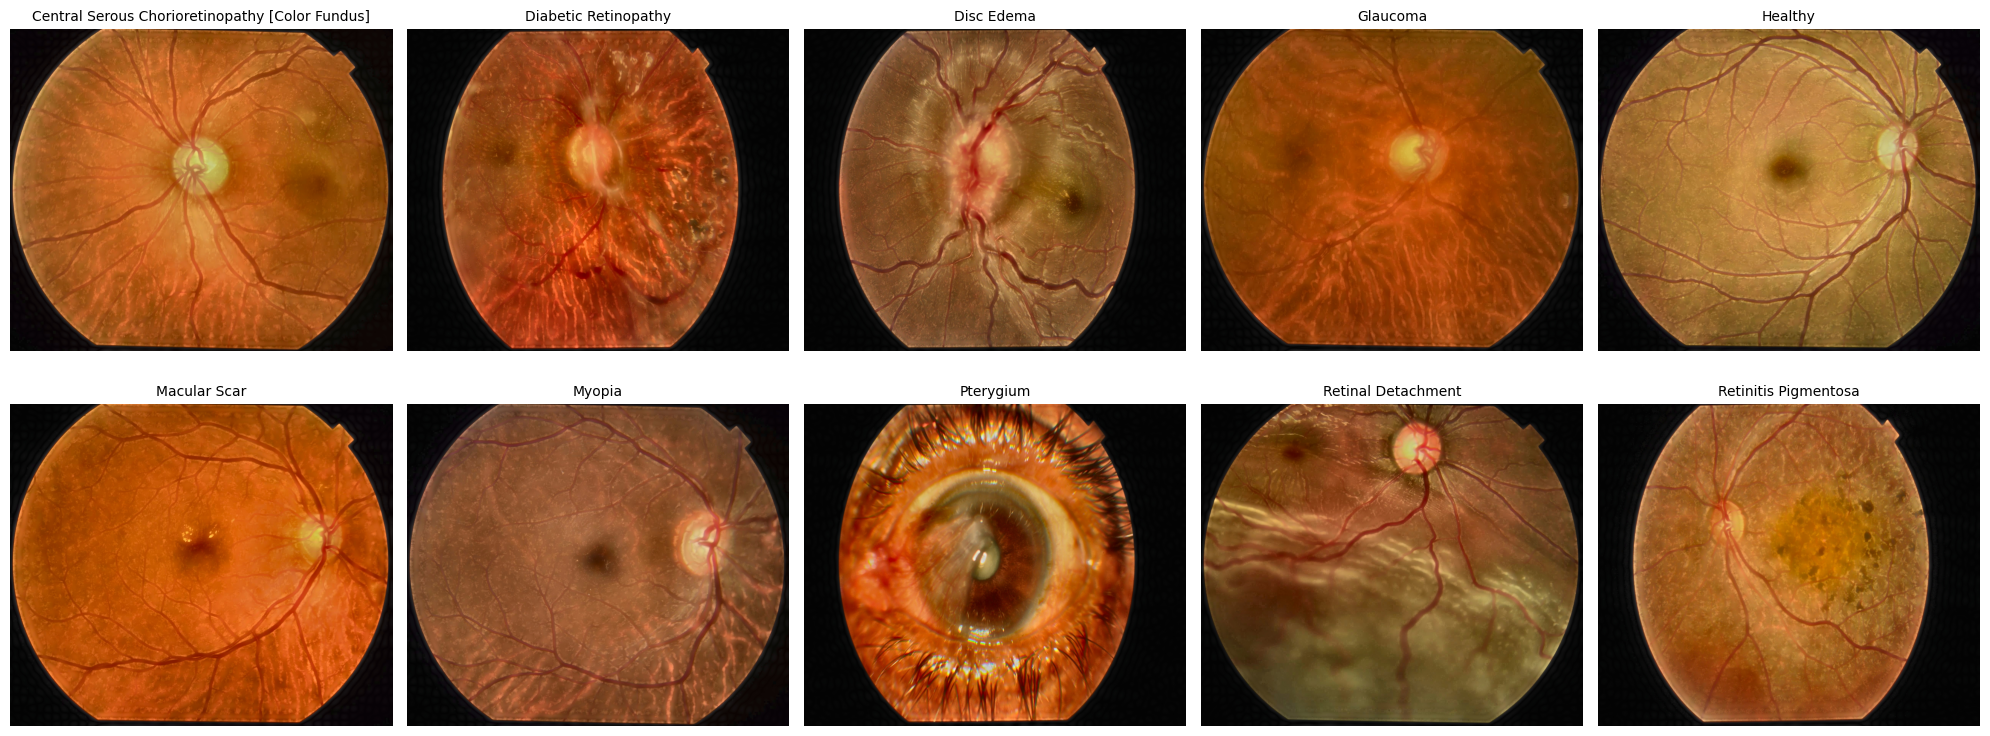

In [ ]:
def show_clean_samples(subset_dataset, class_names):
    # Identify one subset index for each class
    samples_by_class = {}
    indices_to_check = list(range(len(subset_dataset)))
    random.shuffle(indices_to_check)
    
    print("Searching for samples...")
    for idx in indices_to_check:
        if len(samples_by_class) == len(class_names):
            break
            
        # Get label from the subset 
        _, label = subset_dataset[idx]
        
        if label not in samples_by_class:
            samples_by_class[label] = idx

    sorted_labels = sorted(samples_by_class.keys())

    
    plt.figure(figsize=(20, 8))
    
    for i, label in enumerate(sorted_labels):
        subset_idx = samples_by_class[label]
        
        # MAGIC TRICK TO BYPASS AUGMENTATION 
        real_idx = subset_dataset.indices[subset_idx]
        
        # Access the underlying ImageFolder to get the file path
        img_path, _ = subset_dataset.dataset.samples[real_idx]
        
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) 
        

        plt.subplot(2, 5, i + 1)
        plt.imshow(img)
        plt.title(f"{class_names[label]}", fontsize=10)
        plt.axis('off')
    
    plt.tight_layout()
    plt.show()


show_clean_samples(train_dataset, global_classes)

### Convultion trained with pretrained model parameteres to learn the features of eye 

In [26]:
model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
for param in model.features.parameters():
    param.requires_grad = True

num_filters = model.classifier.in_features
model.classifier = nn.Linear(num_filters, number_of_classes)
model = model.to(device)
# print("Model details")
# print(model)


criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=base_learning_rate)


train_acc_list, val_acc_list = [], []
train_loss_list, val_loss_list = [], []

for epoch in range(epochs):
    print(f"\nEpoch {epoch+1}/{epochs}")
    #training the model
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1} Training"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()


        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels).item()
        total += labels.size(0)


    train_acc = correct / total
    train_loss = running_loss / total
    train_acc_list.append(train_acc)
    train_loss_list.append(train_loss)

    #evaluation
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1} validation"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels).item()
            val_total += labels.size(0)



        val_acc = val_correct / val_total
        val_loss /= val_total
        val_acc_list.append(val_acc)
        val_loss_list.append(val_loss)


        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

denseNet121_without_preprocessing_results = {"dense_train_acc": train_acc_list, "dense_val_acc": val_acc_list, "model": model}


Epoch 1/10


Epoch 1 validation: 100%|██████████| 25/25 [00:36<00:00,  1.47s/it]


Train Loss: 1.0521, Train Acc: 0.6394
Val Loss: 0.7571, Val Acc: 0.7262

Epoch 2/10


Epoch 2 validation: 100%|██████████| 25/25 [00:36<00:00,  1.45s/it]


Train Loss: 0.6556, Train Acc: 0.7614
Val Loss: 0.6450, Val Acc: 0.7600

Epoch 3/10


Epoch 3 validation: 100%|██████████| 25/25 [00:36<00:00,  1.46s/it]


... (11 outputs left out)

Epoch 9 validation: 100%|██████████| 25/25 [00:37<00:00,  1.52s/it]


Train Loss: 0.3492, Train Acc: 0.8627
Val Loss: 0.6436, Val Acc: 0.7762

Epoch 10/10


Epoch 10 validation: 100%|██████████| 25/25 [00:37<00:00,  1.50s/it]

Train Loss: 0.3278, Train Acc: 0.8710
Val Loss: 0.7186, Val Acc: 0.7512


In [29]:
torch.save(model, 'eye_denseNet_without_preprocess')

### DenseNet121 with Preprocessed and calculated weights

In [50]:
all_targets = [full_dataset.targets[i] for i in train_indices]
class_counts = Counter(all_targets)
sorted_counts = [class_counts[i] for i in range(number_of_classes)]
total_samples = len(all_targets)

weights = [total_samples / (number_of_classes * count) if count > 0 else 1.0 for count in sorted_counts]
class_weights = torch.FloatTensor(weights).to(device)
print(f"Weights applied: {weights}")


fourier_model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)

for param in fourier_model.parameters():
    param.requires_grad = True


num_filters = fourier_model.classifier.in_features
fourier_model.classifier = nn.Linear(num_filters, number_of_classes)
fourier_model = fourier_model.to(device)


criterion = nn.CrossEntropyLoss(weight=class_weights) 
optimizer = optim.Adam(fourier_model.parameters(), lr=1e-4) 


scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.1, patience=3)




train_acc_list, val_acc_list = [], []
train_loss_list, val_loss_list = [], []

for epoch in range(epochs):
    print(f"\nEpoch {epoch+1}/{epochs}")
    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1} - Current Learning Rate: {current_lr}")
    
    # Training
    fourier_model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for images, labels in tqdm(train_loader, desc=f"Training"):
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = fourier_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels).item()
        total += labels.size(0)

    train_acc = correct / total
    train_loss = running_loss / total
    train_acc_list.append(train_acc)
    train_loss_list.append(train_loss)

    # Validation
    fourier_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Validation"):
            images, labels = images.to(device), labels.to(device)
            outputs = fourier_model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels).item()
            val_total += labels.size(0)

    val_acc = val_correct / val_total
    val_loss /= val_total
    val_acc_list.append(val_acc)
    val_loss_list.append(val_loss)
    
    # Step the scheduler based on Accuracy
    scheduler.step(val_acc)

    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

fourier_model_results = {"fourier_train_acc": train_acc_list, "fourier_val_acc": val_acc_list, "model": fourier_model}

PATH = "fourier_model_weights.pth"
torch.save(fourier_model.state_dict(), PATH)

Weights applied: [5.335714285714285, 0.3497191011235955, 4.196629213483146, 0.39069037656903766, 0.5358680057388809, 1.2618243243243243, 1.055084745762712, 28.73076923076923, 4.293103448275862, 3.557142857142857]

Epoch 1/10
Epoch 1 - Current Learning Rate: 0.0001


Validation: 100%|██████████| 25/25 [00:40<00:00,  1.60s/it]


Train Loss: 1.3493, Train Acc: 0.5481
Val Loss: 0.7968, Val Acc: 0.6475

Epoch 2/10
Epoch 2 - Current Learning Rate: 0.0001


Validation: 100%|██████████| 25/25 [00:36<00:00,  1.48s/it]


Train Loss: 0.6521, Train Acc: 0.7157
Val Loss: 0.6036, Val Acc: 0.7075

Epoch 3/10
Epoch 3 - Current Learning Rate: 0.0001


Validation: 100%|██████████| 25/25 [00:37<00:00,  1.50s/it]


... (11 outputs left out)

Validation: 100%|██████████| 25/25 [00:38<00:00,  1.55s/it]


Train Loss: 0.2872, Train Acc: 0.8461
Val Loss: 0.6325, Val Acc: 0.7137

Epoch 10/10
Epoch 10 - Current Learning Rate: 0.0001


Validation: 100%|██████████| 25/25 [00:36<00:00,  1.45s/it]

Train Loss: 0.2596, Train Acc: 0.8506
Val Loss: 0.6169, Val Acc: 0.7300


Mapping test dataset classes...
Randomly selected classes: [4, 3, 0, 8]
Class Names: ['Healthy', 'Glaucoma', 'Color Fundus', 'Retinal Detachment']


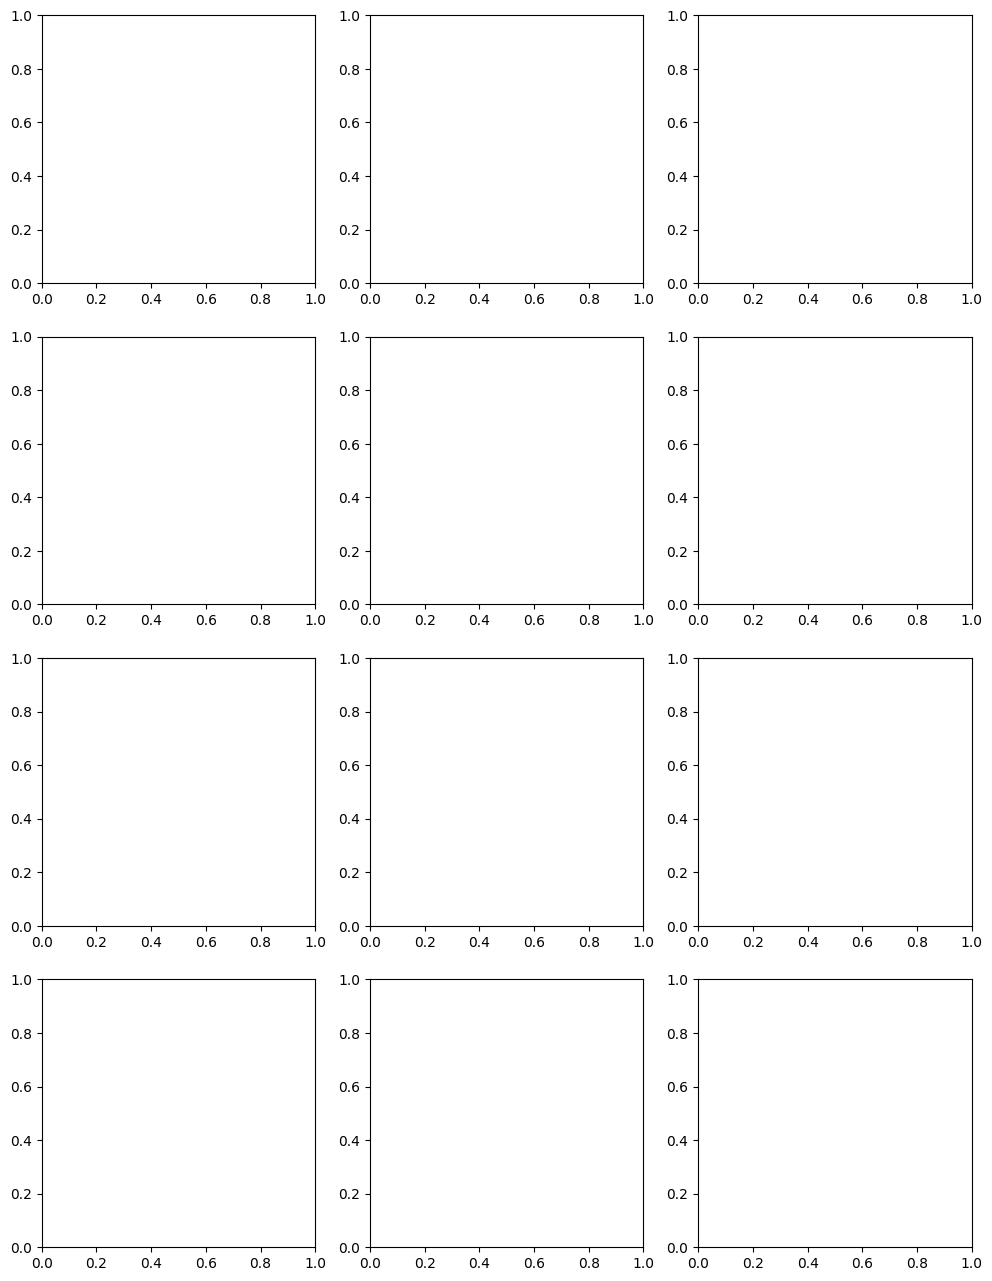

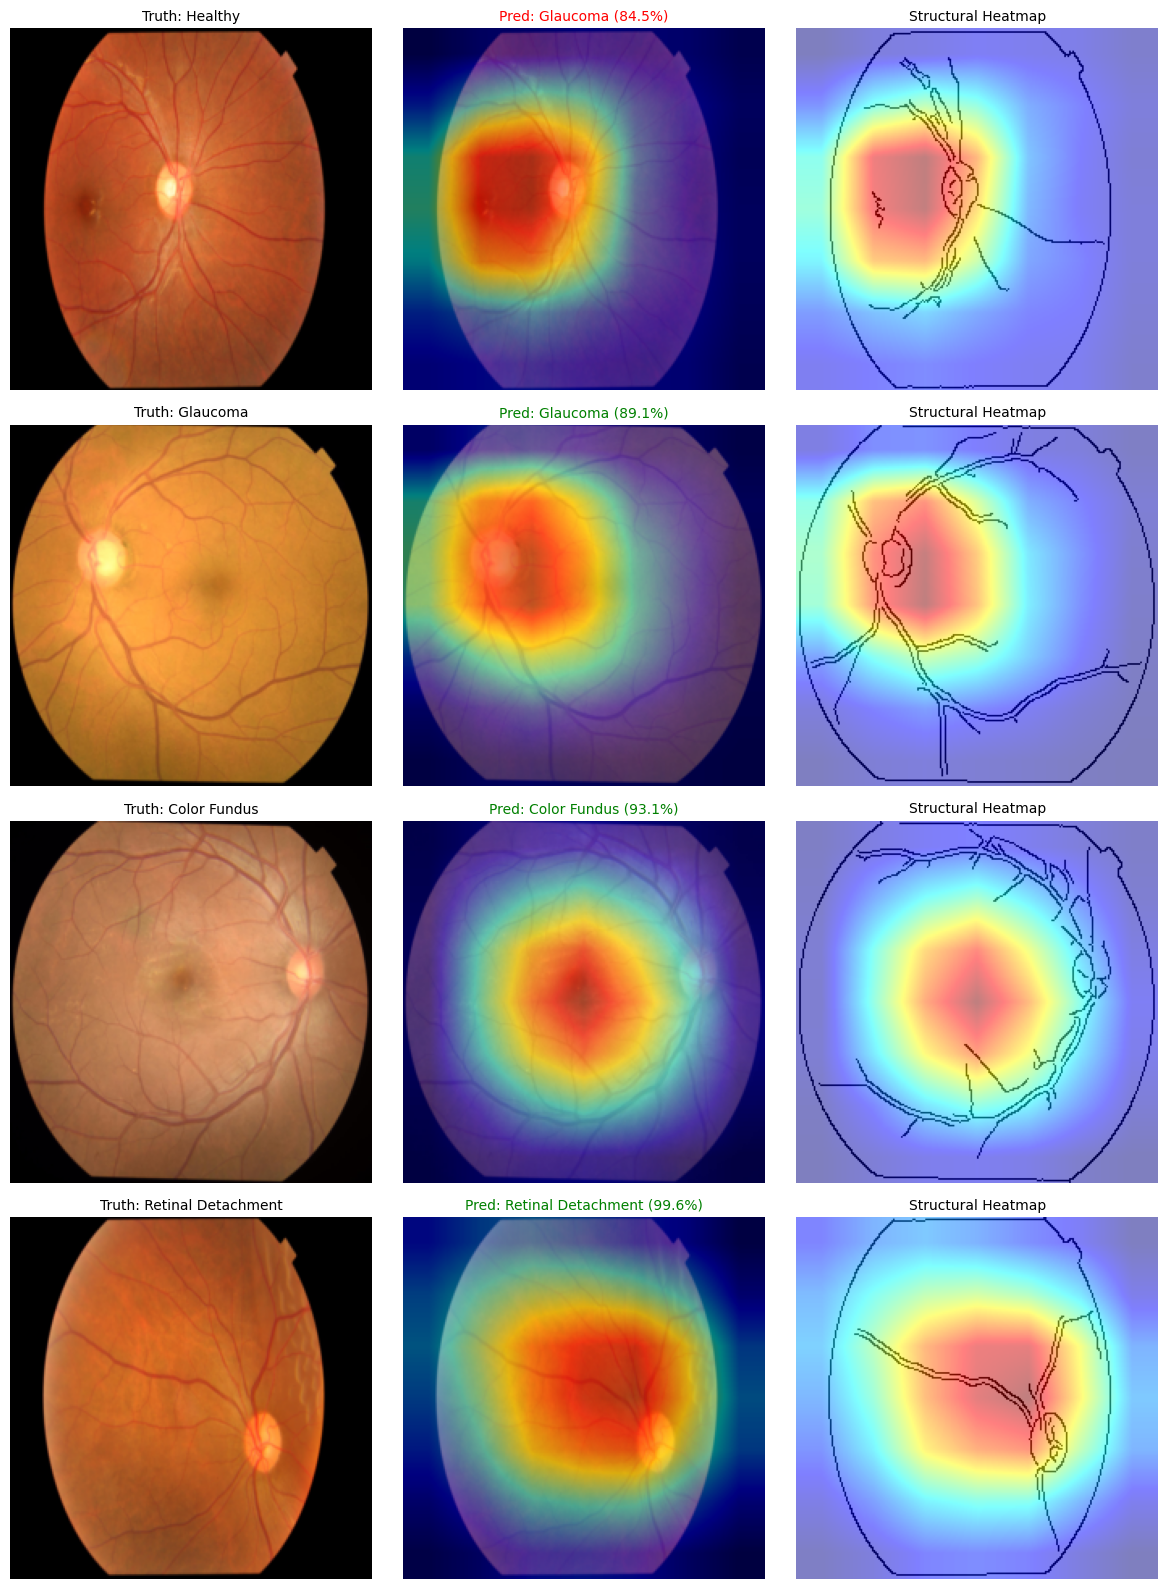

In [ ]:
def unnormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1).to(tensor.device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1).to(tensor.device)
    res = tensor * std + mean
    return torch.clamp(res, 0, 1)

def get_canny_edge(img_tensor):
    img = unnormalize(img_tensor).detach().cpu().permute(1, 2, 0).numpy()
    img_uint8 = (img * 255).astype(np.uint8)        
    gray = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 0)
    edge = cv2.Canny(gray, 30, 80)
    edge = 255 - edge 
    edge = np.stack([edge]*3, axis=-1).astype(np.float32) / 255.0
    return edge


model.eval()


target_layers = [model.features[-1]]


cam = GradCAM(model=model, target_layers=target_layers)


class_to_indices = defaultdict(list)
print("Mapping test dataset classes...")
for i in range(len(test_dataset)):
    _, label = test_dataset[i]
    class_to_indices[label].append(i)


available_classes = list(class_to_indices.keys())


if len(available_classes) < 4:
    print(f"Warning: Only {len(available_classes)} classes found in test set.")
    chosen_classes = available_classes
else:
    chosen_classes = random.sample(available_classes, 4)

print(f"Randomly selected classes: {chosen_classes}")
print(f"Class Names: {[class_names[c] for c in chosen_classes]}")


selected_indices = [] 
for cls in chosen_classes:
    # Pick one random index from the list of indices for this class
    rand_idx = random.choice(class_to_indices[cls])
    selected_indices.append((cls, rand_idx))


num_rows = len(selected_indices)
fig, axes = plt.subplots(num_rows, 3, figsize=(12, 4*num_rows))



num_rows = len(selected_indices)
fig, axes = plt.subplots(num_rows, 3, figsize=(12, 4 * num_rows))


for row_idx, (class_id, img_idx) in enumerate(selected_indices):
    
    
    image, target_label_idx = test_dataset[img_idx]
    
    # Prepare input
    input_tensor = image.unsqueeze(0).to(device)
    input_tensor.requires_grad = True 

    # Prediction
    output = model(input_tensor)
    probabilities = F.softmax(output, dim=1)
    conf, pred_idx = torch.max(probabilities, 1)
    
    target_name = class_names[target_label_idx]
    pred_name = class_names[pred_idx.item()]
    conf_percent = conf.item() * 100

    
    targets = [ClassifierOutputTarget(pred_idx.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    heatmap = grayscale_cam[0, :] 

    
    rgb_img = unnormalize(image).permute(1, 2, 0).cpu().numpy()
    edge_img = get_canny_edge(image)

    # Overlays
    viz_rgb = show_cam_on_image(rgb_img, heatmap, use_rgb=True)
    viz_edge = show_cam_on_image(edge_img, heatmap, use_rgb=True)

    
    if num_rows == 1:
        ax_list = axes
    else:
        ax_list = axes[row_idx]

    # Plot Column 1: Original
    ax_list[0].imshow(rgb_img)
    ax_list[0].set_title(f"Truth: {target_name}", fontsize=10)
    ax_list[0].axis("off")

    # Plot Column 2: Grad-CAM RGB
    ax_list[1].imshow(viz_rgb)
    color = 'green' if target_label_idx == pred_idx.item() else 'red'
    ax_list[1].set_title(f"Pred: {pred_name} ({conf_percent:.1f}%)", color=color, fontsize=10)
    ax_list[1].axis("off")

    # Plot Column 3: Grad-CAM Edges
    ax_list[2].imshow(viz_edge)
    ax_list[2].set_title(f"Structural Heatmap", fontsize=10)
    ax_list[2].axis("off")

plt.tight_layout()
plt.show()

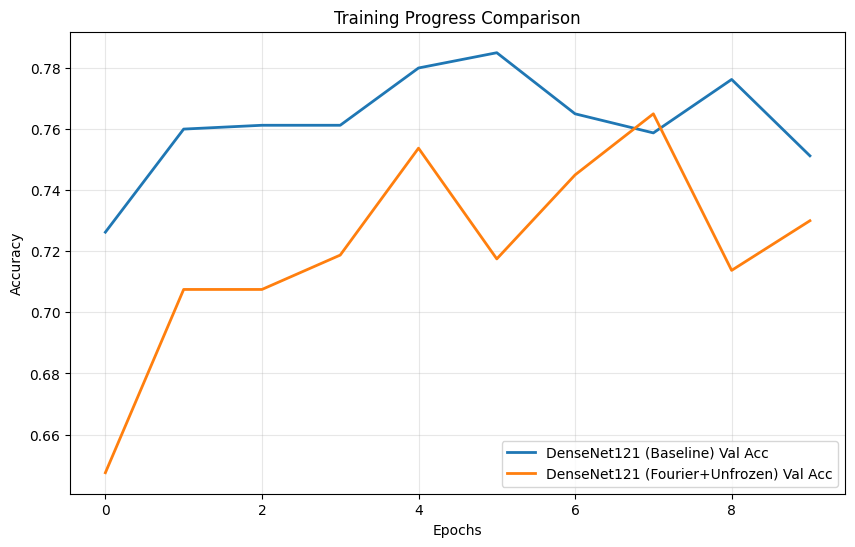


Processing Metrics for: DenseNet121 (Baseline)


Evaluating: 100%|██████████| 800/800 [00:46<00:00, 17.22it/s]



Accuracy: 0.7075
Macro Precision: 0.7915
Macro Recall:    0.7335
Macro F1 Score:  0.7141


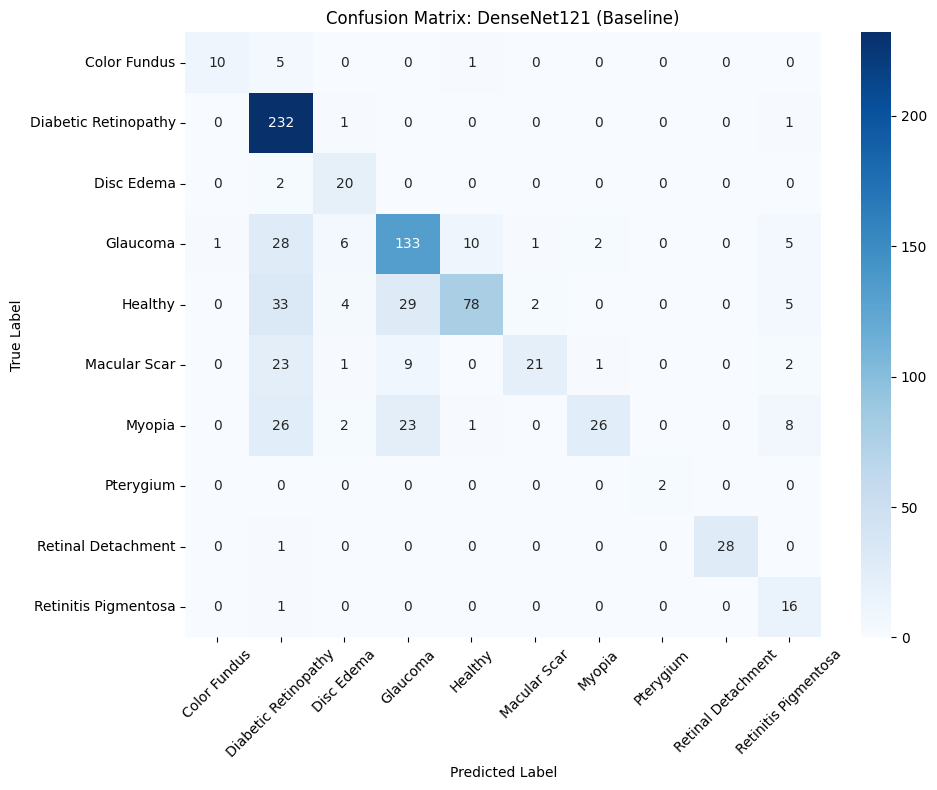

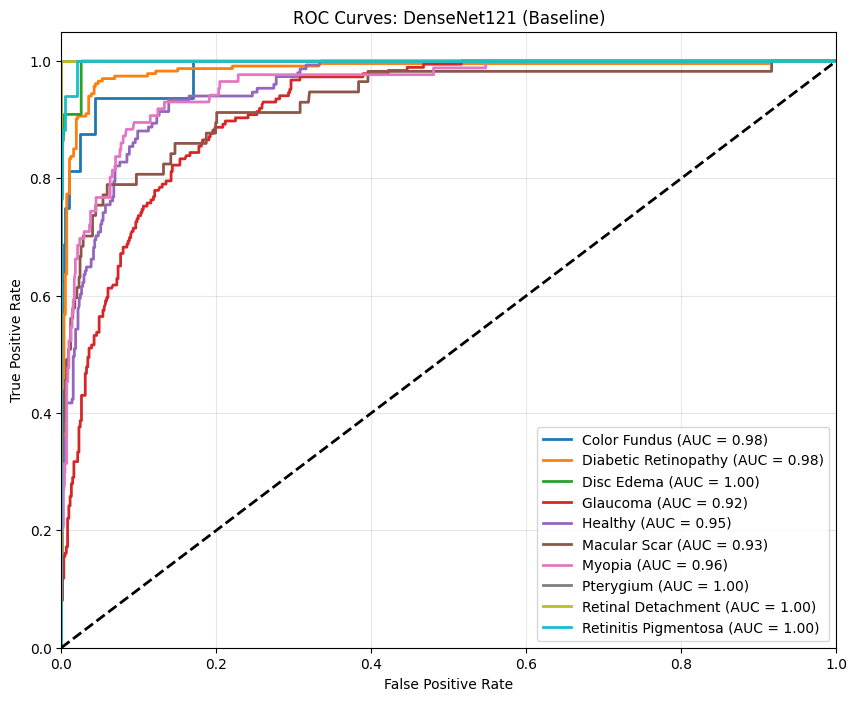


Detailed Classification Report for DenseNet121 (Baseline):
                      precision    recall  f1-score   support

        Color Fundus       0.91      0.62      0.74        16
Diabetic Retinopathy       0.66      0.99      0.79       234
          Disc Edema       0.59      0.91      0.71        22
            Glaucoma       0.69      0.72      0.70       186
             Healthy       0.87      0.52      0.65       151
        Macular Scar       0.88      0.37      0.52        57
              Myopia       0.90      0.30      0.45        86
           Pterygium       1.00      1.00      1.00         2
  Retinal Detachment       1.00      0.97      0.98        29
Retinitis Pigmentosa       0.43      0.94      0.59        17

            accuracy                           0.71       800
           macro avg       0.79      0.73      0.71       800
        weighted avg       0.76      0.71      0.69       800


Processing Metrics for: DenseNet121 (Fourier+Unfrozen)


Evaluating: 100%|██████████| 800/800 [00:44<00:00, 18.12it/s]



Accuracy: 0.8588
Macro Precision: 0.8576
Macro Recall:    0.8909
Macro F1 Score:  0.8730


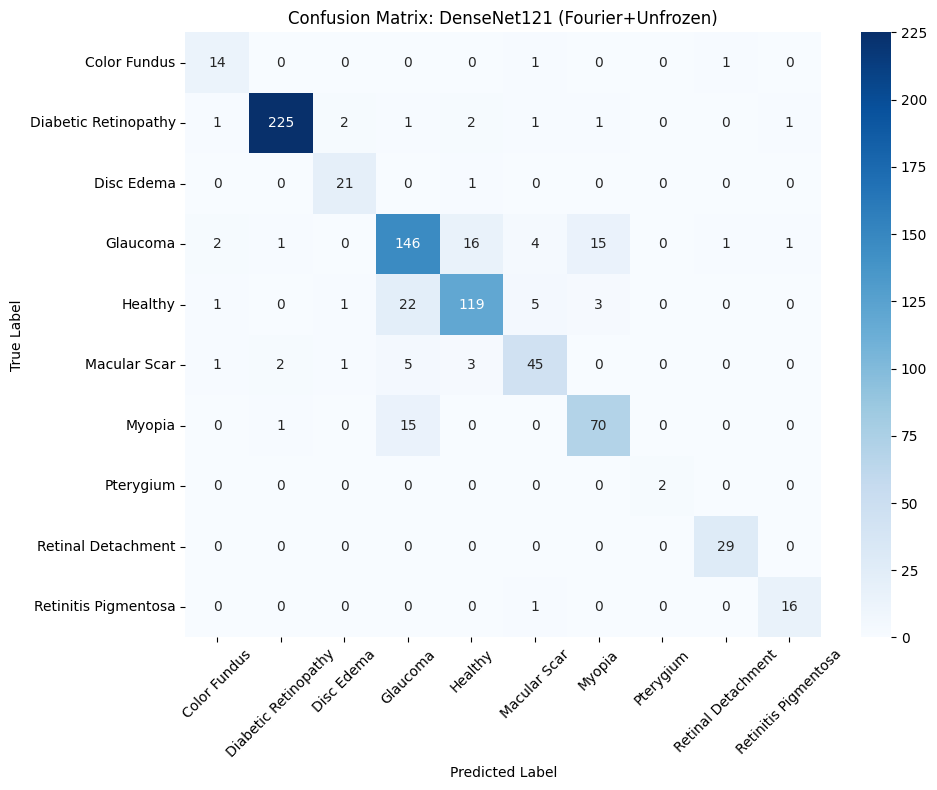

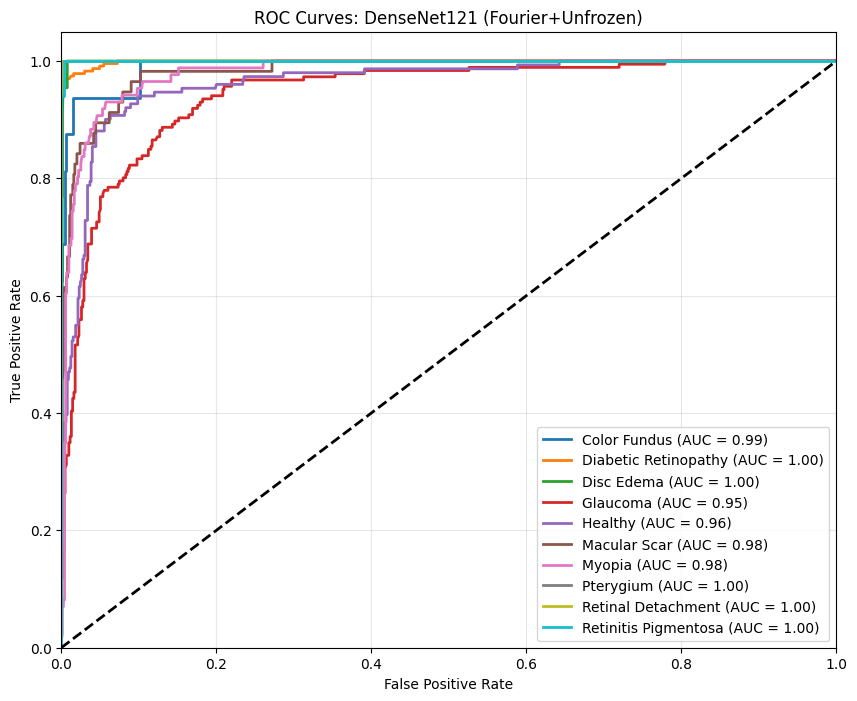


Detailed Classification Report for DenseNet121 (Fourier+Unfrozen):
                      precision    recall  f1-score   support

        Color Fundus       0.74      0.88      0.80        16
Diabetic Retinopathy       0.98      0.96      0.97       234
          Disc Edema       0.84      0.95      0.89        22
            Glaucoma       0.77      0.78      0.78       186
             Healthy       0.84      0.79      0.82       151
        Macular Scar       0.79      0.79      0.79        57
              Myopia       0.79      0.81      0.80        86
           Pterygium       1.00      1.00      1.00         2
  Retinal Detachment       0.94      1.00      0.97        29
Retinitis Pigmentosa       0.89      0.94      0.91        17

            accuracy                           0.86       800
           macro avg       0.86      0.89      0.87       800
        weighted avg       0.86      0.86      0.86       800


Final Comparison Summary:
                            Model 

In [ ]:
eval_list = [
    {
        "name": "DenseNet121 (Baseline)", 
        "model": denseNet121_without_preprocessing_results["model"], 
        "val_acc_history": denseNet121_without_preprocessing_results["dense_val_acc"]
    },

    {
       "name": "DenseNet121 (Fourier+Unfrozen)", 
       "model": fourier_model_results["model"], 
       "val_acc_history": fourier_model_results["fourier_val_acc"]
    }
]


plt.figure(figsize=(10, 6))
for item in eval_list:
    if "val_acc_history" in item and item["val_acc_history"]:
        plt.plot(item["val_acc_history"], label=f"{item['name']} Val Acc", linewidth=2)
plt.title("Training Progress Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


comparison_metrics = []

for item in eval_list:
    name = item["name"]
    model_eval = item["model"]
    model_eval = model_eval.to(device)
    model_eval.eval()
    
    print(f"\n" + "="*40)
    print(f"Processing Metrics for: {name}")
    print("="*40)

    
    y_true = []
    y_pred = []
    y_probs = []
    
    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Evaluating"):
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model_eval(images)
            
            
            probs = torch.softmax(outputs, dim=1)
            y_probs.extend(probs.cpu().numpy())
            
            
            preds = torch.argmax(outputs, dim=1)
            y_pred.extend(preds.cpu().numpy())
            y_true.extend(labels.cpu().numpy())
            
 
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_probs = np.array(y_probs)

    
    acc = accuracy_score(y_true, y_pred)
   
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')
    
 
    precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')

    print(f"\nAccuracy: {acc:.4f}")
    print(f"Macro Precision: {precision_macro:.4f}")
    print(f"Macro Recall:    {recall_macro:.4f}")
    print(f"Macro F1 Score:  {f1_macro:.4f}")
    
    
    comparison_metrics.append({
        "Model": name,
        "Accuracy": acc,
        "Macro Precision": precision_macro,
        "Macro Recall": recall_macro,
        "Macro F1": f1_macro,
        "Weighted F1": f1_weighted
    })

   
    plt.figure(figsize=(10, 8))
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title(f"Confusion Matrix: {name}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    
    y_true_bin = label_binarize(y_true, classes=range(len(class_names)))
    
    plt.figure(figsize=(10, 8))
    
   
    for i in range(len(class_names)):
  
        if np.sum(y_true == i) > 0:
            fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, lw=2, label=f'{class_names[i]} (AUC = {roc_auc:.2f})')
    
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curves: {name}')
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.show()

    
    print(f"\nDetailed Classification Report for {name}:")
    print(classification_report(y_true, y_pred, target_names=class_names))


df_results = pd.DataFrame(comparison_metrics)
print("\nFinal Comparison Summary:")
print(df_results)

## Generalized evaluations

In [5]:
def run_evaluation_metrics(y_true, y_preds, y_probs, class_names, model):

    num_classes = len(class_names)
    
    # 1. Calculate Metrics
    accuracy = accuracy_score(y_true, y_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_preds, average=None)
    macro_f1 = f1.mean()
    weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(y_true, y_preds, average='weighted')
    kappa = cohen_kappa_score(y_true, y_preds)
    mcc = matthews_corrcoef(y_true, y_preds)
    
    # Sensitivity & Specificity
    sensitivity = sensitivity_score(y_true, y_preds, average='macro')
    specificity = specificity_score(y_true, y_preds, average='macro')

    # AUC Scores
    try:
        auc_ovr = roc_auc_score(y_true, y_probs, multi_class='ovr', average='weighted')
        auc_macro = roc_auc_score(y_true, y_probs, multi_class='ovr', average='macro')
        auc_weighted = roc_auc_score(y_true, y_probs, multi_class='ovr', average='weighted')
    except Exception as e:
        print(f"Could not calculate AUC: {e}")
        auc_ovr, auc_macro, auc_weighted = 0, 0, 0

    # 2. Print Text Report
    print(f"\n{'='*10} RESULTS FOR: {model} {'='*10}")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"Cohen's Kappa: {kappa:.4f}")
    print(f"MCC: {mcc:.4f}")
    print(f"Macro Sensitivity (Recall): {sensitivity:.4f}")
    print(f"Macro Specificity: {specificity:.4f}")
    print("\nPer-Class Performance:")
    for i, name in enumerate(class_names):
        print(f"  {name:15s}  Precision: {precision[i]:.4f}  Recall: {recall[i]:.4f}  F1: {f1[i]:.4f}")
    print(f"\nMacro F1-score: {macro_f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")
    print(f"Weighted AUC: {auc_ovr:.4f}")
    print(f"Macro AUC (OvR): {auc_macro:.4f}")
    print(f"Weighted AUC (OvR): {auc_weighted:.4f}")
    
    print("\nClassification Report:\n")
    print(classification_report(y_true, y_preds, target_names=class_names))

    #  Plot Confusion Matrix
    cm = confusion_matrix(y_true, y_preds)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'{model}: Confusion Matrix (Acc: {accuracy:.4f})')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # Plot ROC Curves
    y_true_bin = label_binarize(y_true, classes=range(num_classes))
    
    plt.figure(figsize=(12, 10))
    colors = plt.cm.tab10(np.linspace(0, 1, num_classes))

    for i, color in zip(range(num_classes), colors):
        if np.sum(y_true == i) > 0: # Only plot if class exists in test set
            fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, color=color, lw=2, 
                     label=f'{class_names[i]} (AUC = {roc_auc:.2f})')
    
    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Chance')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{model}: ROC Curves')
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.show()

### Using Augmented dataset

### Using K-fold dataset for proper distribution

In [4]:
temp_dataset = datasets.ImageFolder(root=dataset_dir)
targets = [s[1] for s in temp_dataset.samples]
dataset_indices = np.arange(len(targets))
class_names = temp_dataset.classes
number_of_classes = len(class_names)
targets = [s[1] for s in temp_dataset.samples]
print(f"Classes: {class_names}")



sss = StratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
dev_indices, test_indices = next(sss.split(dataset_indices, targets))


print(f"Total Data: {len(targets)}")
print(f"K-Fold Development Data: {len(dev_indices)}")
print(f"Hold-Out Test Data: {len(test_indices)}")


train_dataset_source = datasets.ImageFolder(root=dataset_dir, transform=train_transforms)
val_test_dataset_source = datasets.ImageFolder(root=dataset_dir, transform=val_test_transforms)


test_dataset = Subset(val_test_dataset_source, test_indices)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=num_workers)


k_folds = 5
kfold = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)


dev_targets = [targets[i] for i in dev_indices]


fold_results = []




for fold, (fold_train_idx_rel, fold_val_idx_rel) in enumerate(kfold.split(dev_indices, dev_targets)):
    

    
    # Map relative indices back to original dataset indices
    train_indices = dev_indices[fold_train_idx_rel]
    val_indices = dev_indices[fold_val_idx_rel]
    
    # Dynamic Class Weights (Calculated per fold) ---
    fold_train_targets = [targets[i] for i in train_indices]
    class_weights_arr = compute_class_weight('balanced', classes=np.unique(fold_train_targets), y=fold_train_targets)
    class_weights = torch.tensor(class_weights_arr, dtype=torch.float).to(device)
    
 
    # Train subset uses train_transforms
    train_subset = Subset(train_dataset_source, train_indices)
    # Val subset uses val_test_transforms
    val_subset = Subset(val_test_dataset_source, val_indices)
    

    train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True)
    val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    



Classes: ['Color Fundus', 'Diabetic Retinopathy', 'Disc Edema', 'Glaucoma', 'Healthy', 'Macular Scar', 'Myopia', 'Pterygium', 'Retinal Detachment', 'Retinitis Pigmentosa']
Total Data: 16242
K-Fold Development Data: 13805
Hold-Out Test Data: 2437


### Traditional Feature Extraction(HOG, GLCM)

Classes found: ['Color Fundus', 'Diabetic Retinopathy', 'Disc Edema', 'Glaucoma', 'Healthy', 'Macular Scar', 'Myopia', 'Pterygium', 'Retinal Detachment', 'Retinitis Pigmentosa']


Processing Retinitis Pigmentosa: 100%|██████████| 834/834 [00:49<00:00, 16.79it/s]



Feature Extraction Complete.
Feature Vector Shape: (16242, 1784)
Training SVM on Traditional Features

========== RESULTS FOR: Traditional Features (GLCM+HOG) ==========
Test Accuracy: 0.5463
Cohen's Kappa: 0.4649
MCC: 0.4657
Macro Sensitivity (Recall): 0.5747
Macro Specificity: 0.9462

Per-Class Performance:
  Color Fundus     Precision: 0.3939  Recall: 0.3223  F1: 0.3545
  Diabetic Retinopathy  Precision: 0.6255  Recall: 0.7344  F1: 0.6756
  Disc Edema       Precision: 0.4793  Recall: 0.3791  F1: 0.4234
  Glaucoma         Precision: 0.4023  Recall: 0.4323  F1: 0.4167
  Healthy          Precision: 0.5375  Recall: 0.5626  F1: 0.5498
  Macular Scar     Precision: 0.3729  Recall: 0.2912  F1: 0.3271
  Myopia           Precision: 0.5865  Recall: 0.5800  F1: 0.5832
  Pterygium        Precision: 1.0000  Recall: 1.0000  F1: 1.0000
  Retinal Detachment  Precision: 0.8806  Recall: 0.7867  F1: 0.8310
  Retinitis Pigmentosa  Precision: 0.7914  Recall: 0.6587  F1: 0.7190

Macro F1-score: 0.5880
W

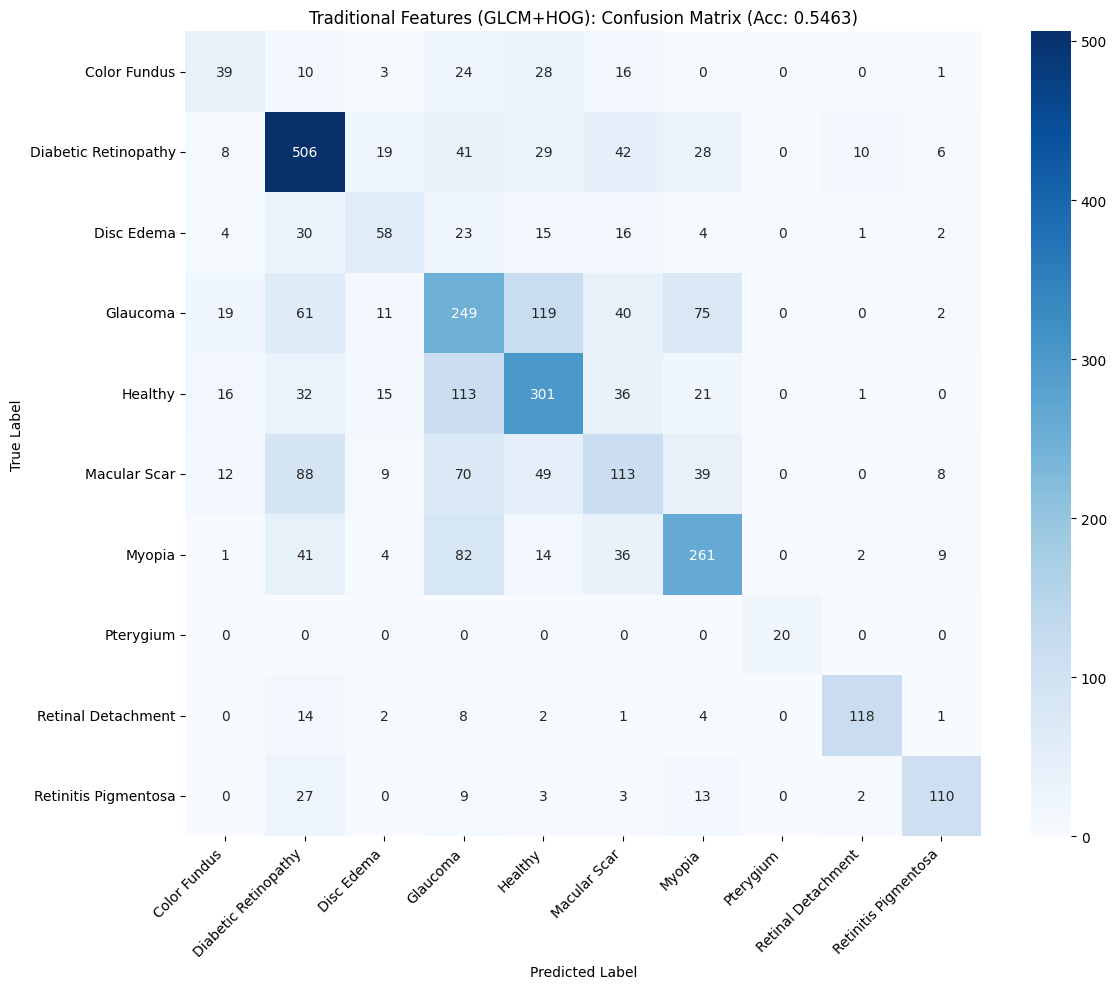

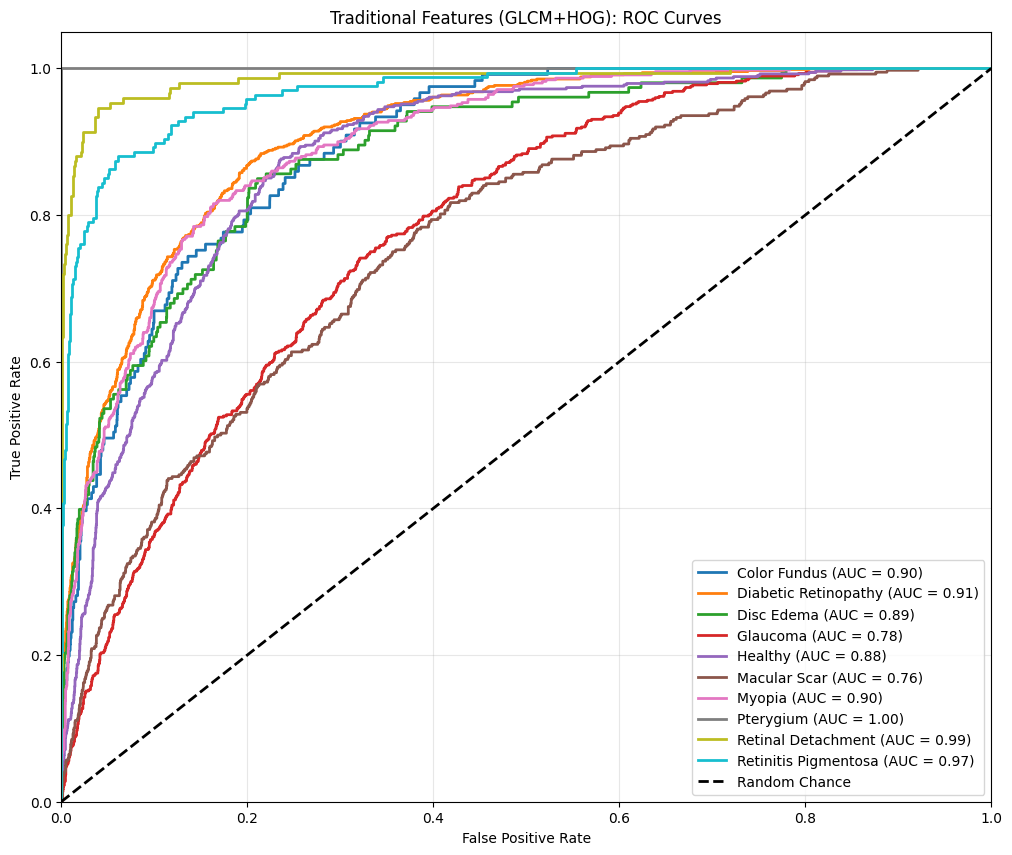

In [19]:
def extract_glcm_features(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    glcm = graycomatrix(gray, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], 
                        levels=256, symmetric=True, normed=True)
    
    contrast = graycoprops(glcm, 'contrast').flatten()
    dissimilarity = graycoprops(glcm, 'dissimilarity').flatten()
    homogeneity = graycoprops(glcm, 'homogeneity').flatten()
    energy = graycoprops(glcm, 'energy').flatten()
    correlation = graycoprops(glcm, 'correlation').flatten()

    return np.hstack([contrast, dissimilarity, homogeneity, energy, correlation])

def extract_hog_features(image):
    resized = cv2.resize(image, (128, 128)) 

    features = hog(resized, orientations=9, pixels_per_cell=(16, 16),
                   cells_per_block=(2, 2), channel_axis=-1, visualize=False)
    
    return features


X_traditional = []
y = []

# Get class names sorted alphabetically to ensure index matches
classes = sorted([d.name for d in dataset_dir.iterdir() if d.is_dir()])
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}

print(f"Classes found: {classes}")

# Extraction Loop
for cls_name in classes:
    cls_folder = dataset_dir / cls_name
    
    img_files = list(cls_folder.glob("*.*"))
    
    for img_path in tqdm(img_files, desc=f"Processing {cls_name}"):
        img = cv2.imread(str(img_path))
        if img is None: continue
            
        # Extract Features
        feat_glcm = extract_glcm_features(img) 
        feat_hog = extract_hog_features(img)   
        
        # Concatenate
        combined_features = np.hstack([feat_glcm, feat_hog])
        
        X_traditional.append(combined_features)
        y.append(class_to_idx[cls_name])

X_traditional = np.array(X_traditional)
y = np.array(y)

print(f"\nFeature Extraction Complete.")
print(f"Feature Vector Shape: {X_traditional.shape}") 



print("Training SVM on Traditional Features")

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X_traditional, y, test_size=0.2, random_state=42, stratify=y)

# Initialize Classifier
basic_clf = SVC(kernel='linear', probability=True, random_state=42) 
basic_clf.fit(X_train, y_train)



# Get Class Predictions 
preds = basic_clf.predict(X_test)

# Get Class Probabilities
# This returns array of shape 
probs = basic_clf.predict_proba(X_test)


run_evaluation_metrics(
    y_true=y_test, 
    y_preds=preds, 
    y_probs=probs, 
    class_names=classes, 
    model="Traditional Features (GLCM+HOG)"
)

## Feature Extraction using Deep CNN as backbone

Extracting CNN Features for Retinitis Pigmentosa: 100%|██████████| 834/834 [00:51<00:00, 16.11it/s]


CNN Features Shape: (16242, 1024)
Accuracy: 0.7892
                      precision    recall  f1-score   support

        Color Fundus       0.69      0.76      0.72       132
Diabetic Retinopathy       0.91      0.93      0.92       659
          Disc Edema       0.90      0.91      0.91       163
            Glaucoma       0.63      0.70      0.66       562
             Healthy       0.74      0.71      0.72       578
        Macular Scar       0.72      0.64      0.68       396
              Myopia       0.81      0.78      0.79       428
           Pterygium       1.00      1.00      1.00        14
  Retinal Detachment       0.95      0.99      0.97       150
Retinitis Pigmentosa       0.96      0.92      0.94       167

            accuracy                           0.79      3249
           macro avg       0.83      0.83      0.83      3249
        weighted avg       0.79      0.79      0.79      3249


========== RESULTS FOR: DenseNet features + SVM (linear) ==========
Test Accu

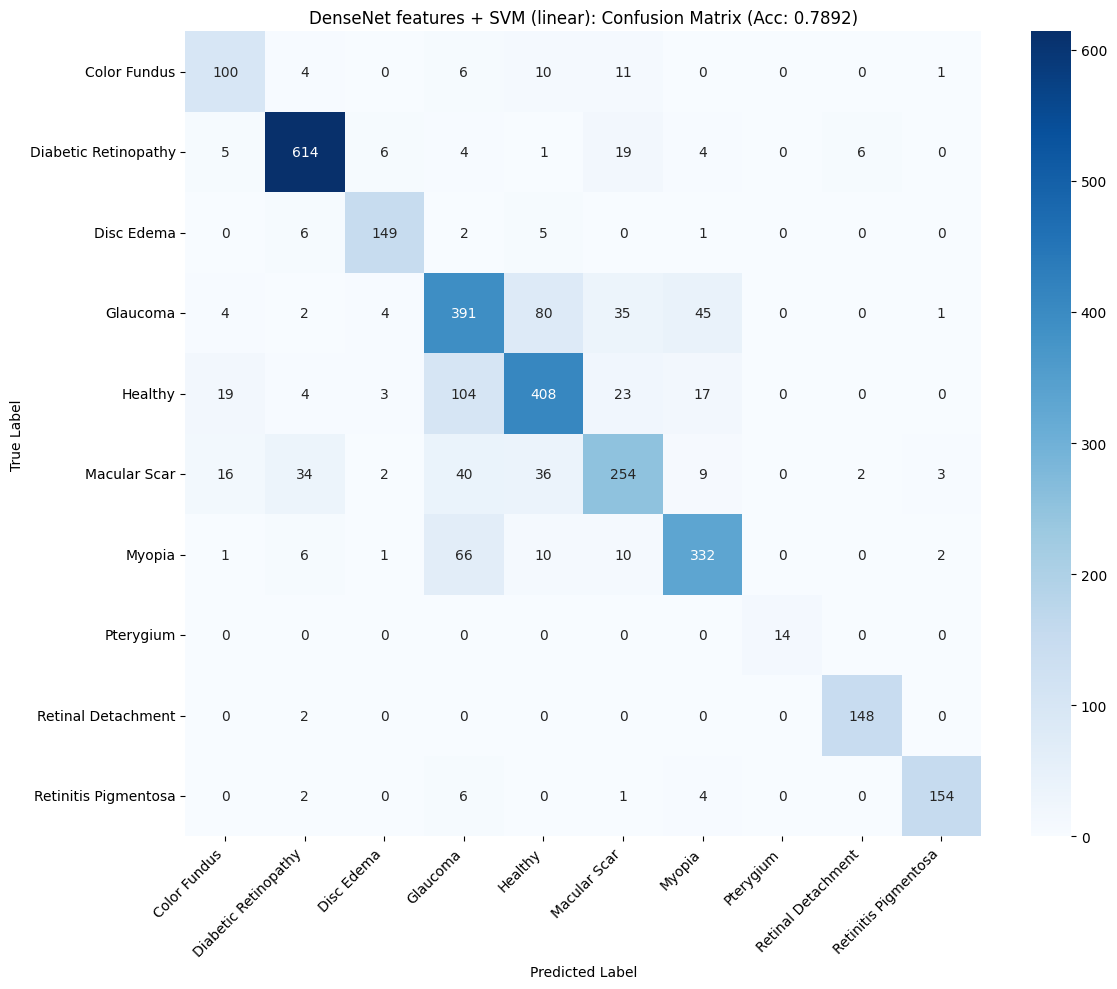

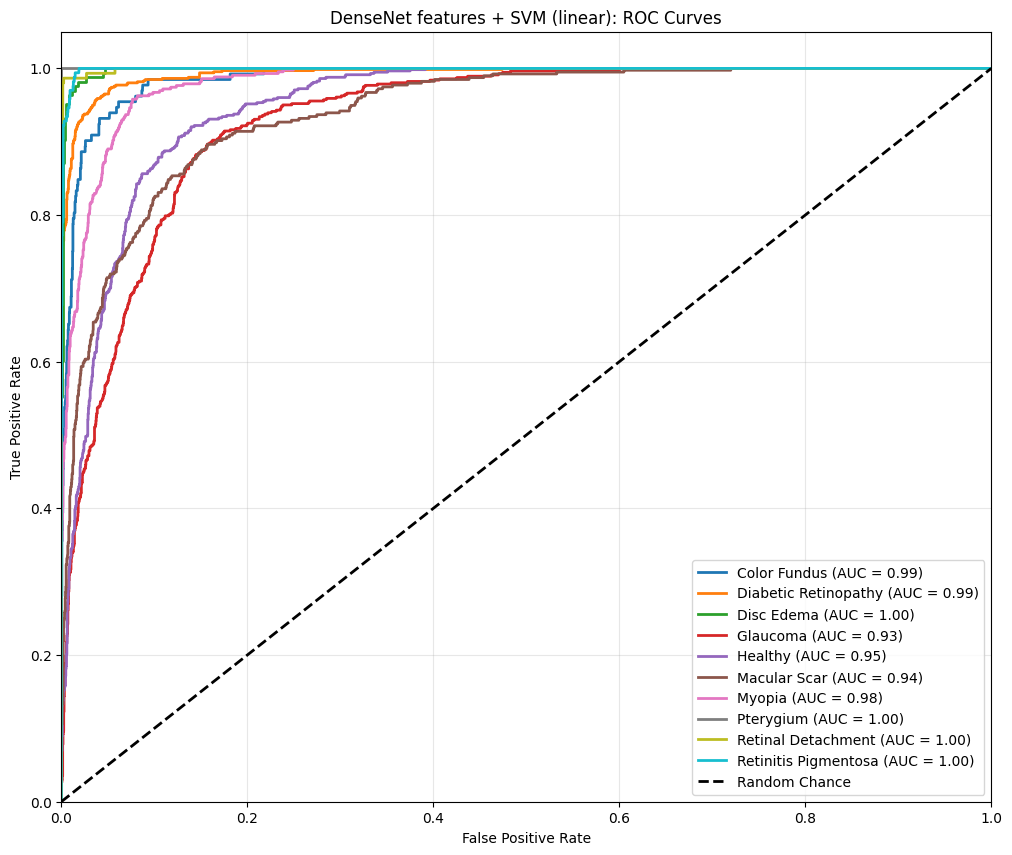

In [20]:
cnn_extractor = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)

# editing the classifier
cnn_extractor.classifier = nn.Identity()
cnn_extractor.to(device)
cnn_extractor.eval()

transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

X_cnn = []
y = []
image_paths = []

classes = sorted([d.name for d in dataset_dir.iterdir() if d.is_dir()])
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}

for cls_name in classes:
    cls_folder = dataset_dir / cls_name

    current_images = list(cls_folder.glob("*.*")) 

    for img_path in tqdm(current_images, desc=f"Extracting CNN Features for {cls_name}"): 
       img = cv2.imread(str(img_path))
       img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

       img_t = transform(img).unsqueeze(0).to(device)

       with torch.no_grad():
        features = cnn_extractor(img_t)
        features = features.cpu().numpy().flatten()

        X_cnn.append(features)
        y.append(class_to_idx[cls_name])
        image_paths.append(str(img_path))

X_cnn = np.array(X_cnn)
y = np.array(y)


print(f"CNN Features Shape: {X_cnn.shape}")

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cnn, y, test_size=0.2, random_state=42)

cnn_clf = SVC(kernel='linear', probability=True) 
cnn_clf.fit(X_train_c, y_train_c)
preds_c = cnn_clf.predict(X_test_c)
probs_c = cnn_clf.predict_proba(X_test_c)


print(f"Accuracy: {accuracy_score(y_test_c, preds_c):.4f}")
print(classification_report(y_test_c, preds_c, target_names=classes))

run_evaluation_metrics(
    y_true=y_test_c,
    y_preds=preds_c,
    y_probs=probs_c,
    class_names=classes,
    model="DenseNet features + SVM (linear)"
)

## Deep Feature extraction with traditional feature extraction using DenseNet121 as CNN backbone

Extracting Deep Features for Color Fundus: 100%|██████████| 606/606 [00:28<00:00, 21.24it/s]
Extracting Deep Features for Diabetic Retinopathy: 100%|██████████| 3444/3444 [02:38<00:00, 21.79it/s]
Extracting Deep Features for Retinal Detachment: 100%|██████████| 750/750 [00:35<00:00, 20.97it/s]
Extracting Deep Features for Retinitis Pigmentosa: 100%|██████████| 834/834 [00:38<00:00, 21.44it/s]


Deep Features Shape: (16242, 1024)

Fusing Features...
Hybrid Feature Vector Shape: (16242, 2808)
Training SVM on HYBRID Features...

 Hybrid Fusion Results
Accuracy: 0.7895
                      precision    recall  f1-score   support

        Color Fundus       0.69      0.80      0.74       132
Diabetic Retinopathy       0.91      0.94      0.92       659
          Disc Edema       0.92      0.92      0.92       163
            Glaucoma       0.63      0.70      0.66       562
             Healthy       0.73      0.69      0.71       578
        Macular Scar       0.72      0.65      0.69       396
              Myopia       0.81      0.76      0.79       428
           Pterygium       1.00      1.00      1.00        14
  Retinal Detachment       0.95      0.99      0.97       150
Retinitis Pigmentosa       0.96      0.92      0.94       167

            accuracy                           0.79      3249
           macro avg       0.83      0.84      0.83      3249
        weighted a

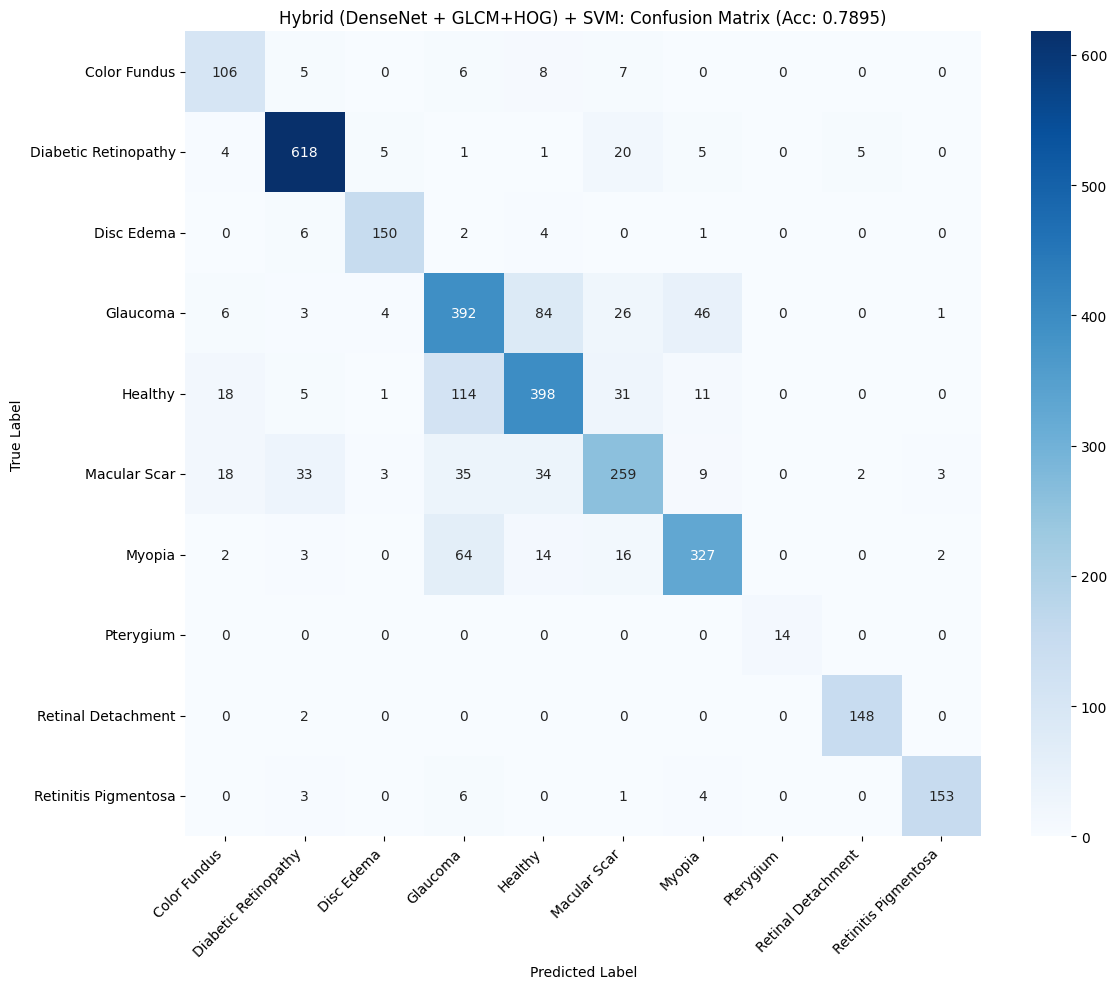

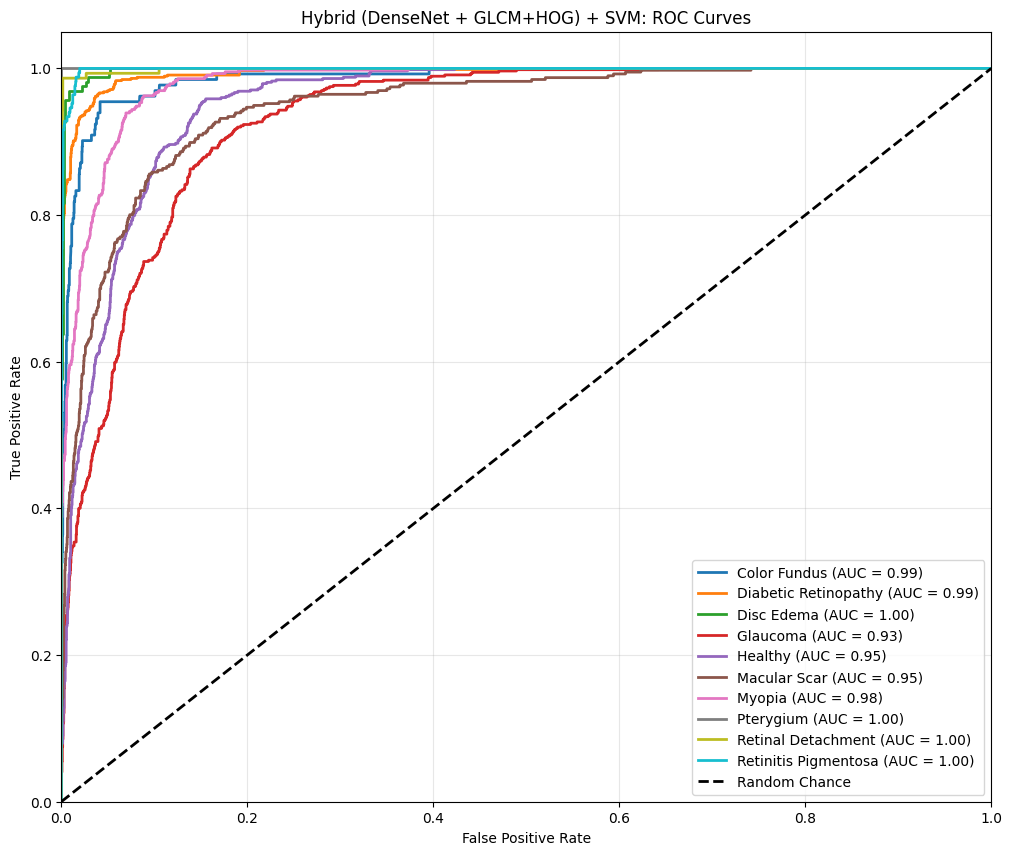

In [21]:
extractor_model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
# changing the classfier
extractor_model.classifier = nn.Identity() 

extractor_model = extractor_model.to(device)
extractor_model.eval()


transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

X_deep = []
y = []
image_paths = []


for cls_name in classes:
    cls_folder = dataset_dir / cls_name
    img_files = list(cls_folder.glob("*.*"))
    for img_path in tqdm(img_files, desc=f"Extracting Deep Features for {cls_name}"):
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_t = transform(img).unsqueeze(0).to(device)
        with torch.no_grad():
            features = extractor_model(img_t).cpu().numpy().flatten()
        X_deep.append(features)
        y.append(class_to_idx[cls_name])


X_deep = np.array(X_deep)
y = np.array(y)
print(f"Deep Features Shape: {X_deep.shape}")


print("\nFusing Features...")
# Combining Deep CNN + Traditional 
X_hybrid = np.hstack([X_deep, X_traditional])
print(f"Hybrid Feature Vector Shape: {X_hybrid.shape}")


print("Training SVM on HYBRID Features...")
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X_hybrid, y, test_size=0.2, random_state=42)

deep_cnn_clf = SVC(kernel='linear', probability=True) 
deep_cnn_clf.fit(X_train_h, y_train_h)
preds_h = deep_cnn_clf.predict(X_test_h)
probs_h = deep_cnn_clf.predict_proba(X_test_h)

print("\n Hybrid Fusion Results")
print(f"Accuracy: {accuracy_score(y_test_h, preds_h):.4f}")
print(classification_report(y_test_h, preds_h, target_names=classes))
run_evaluation_metrics(y_test_h, preds_h, probs_h, classes, "Hybrid (DenseNet + GLCM+HOG) + SVM")

Classes found: ['Color Fundus', 'Diabetic Retinopathy', 'Disc Edema', 'Glaucoma', 'Healthy', 'Macular Scar', 'Myopia', 'Pterygium', 'Retinal Detachment', 'Retinitis Pigmentosa']


Processing Retinitis Pigmentosa: 100%|██████████| 834/834 [01:00<00:00, 13.78it/s]



Feature Extraction Complete.
Feature Vector Shape: (16242, 1784)
Training SVM on Traditional Features

========== RESULTS FOR: Traditional Features (GLCM+HOG) ==========
Test Accuracy: 0.5463
Cohen's Kappa: 0.4649
MCC: 0.4657
Macro Sensitivity (Recall): 0.5747
Macro Specificity: 0.9462

Per-Class Performance:
  Color Fundus     Precision: 0.3939  Recall: 0.3223  F1: 0.3545
  Diabetic Retinopathy  Precision: 0.6255  Recall: 0.7344  F1: 0.6756
  Disc Edema       Precision: 0.4793  Recall: 0.3791  F1: 0.4234
  Glaucoma         Precision: 0.4023  Recall: 0.4323  F1: 0.4167
  Healthy          Precision: 0.5375  Recall: 0.5626  F1: 0.5498
  Macular Scar     Precision: 0.3729  Recall: 0.2912  F1: 0.3271
  Myopia           Precision: 0.5865  Recall: 0.5800  F1: 0.5832
  Pterygium        Precision: 1.0000  Recall: 1.0000  F1: 1.0000
  Retinal Detachment  Precision: 0.8806  Recall: 0.7867  F1: 0.8310
  Retinitis Pigmentosa  Precision: 0.7914  Recall: 0.6587  F1: 0.7190

Macro F1-score: 0.5880
W

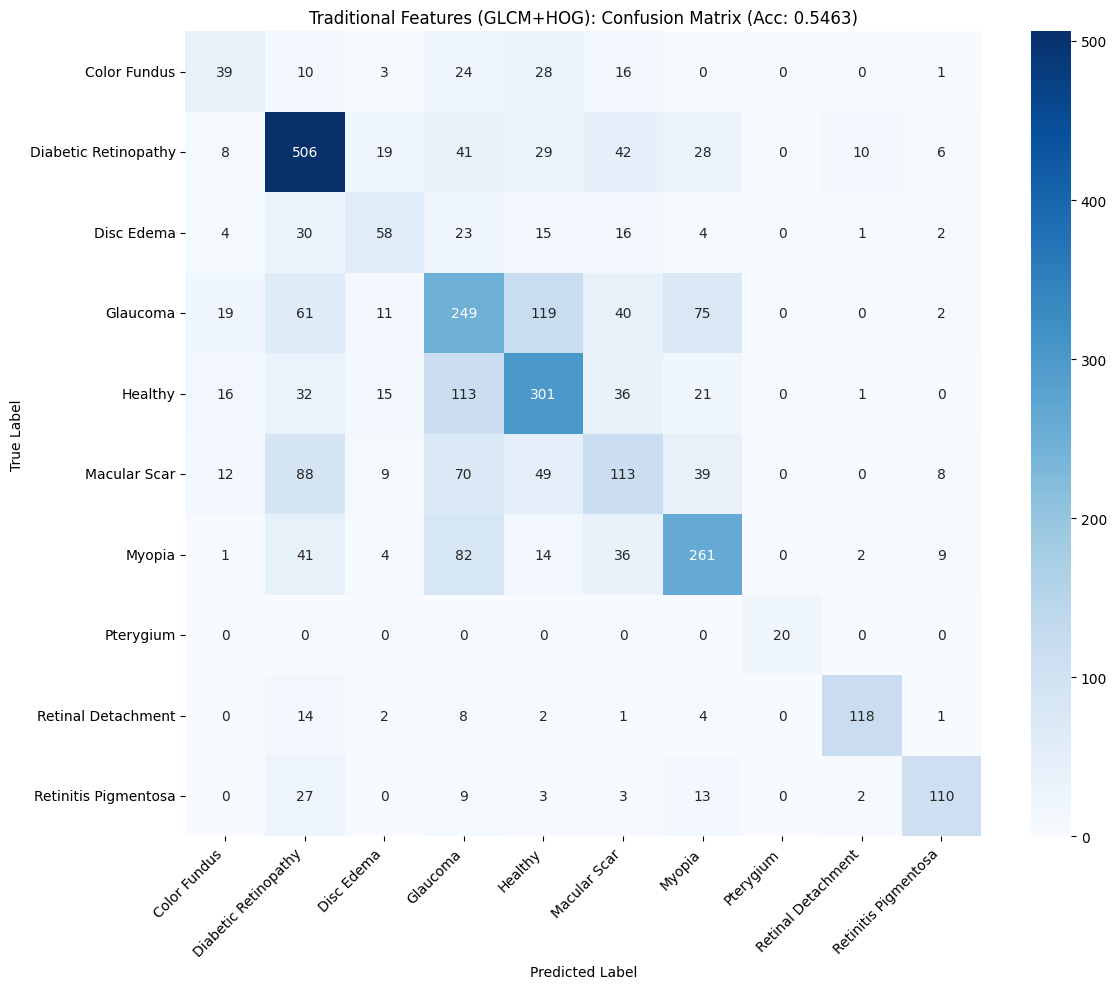

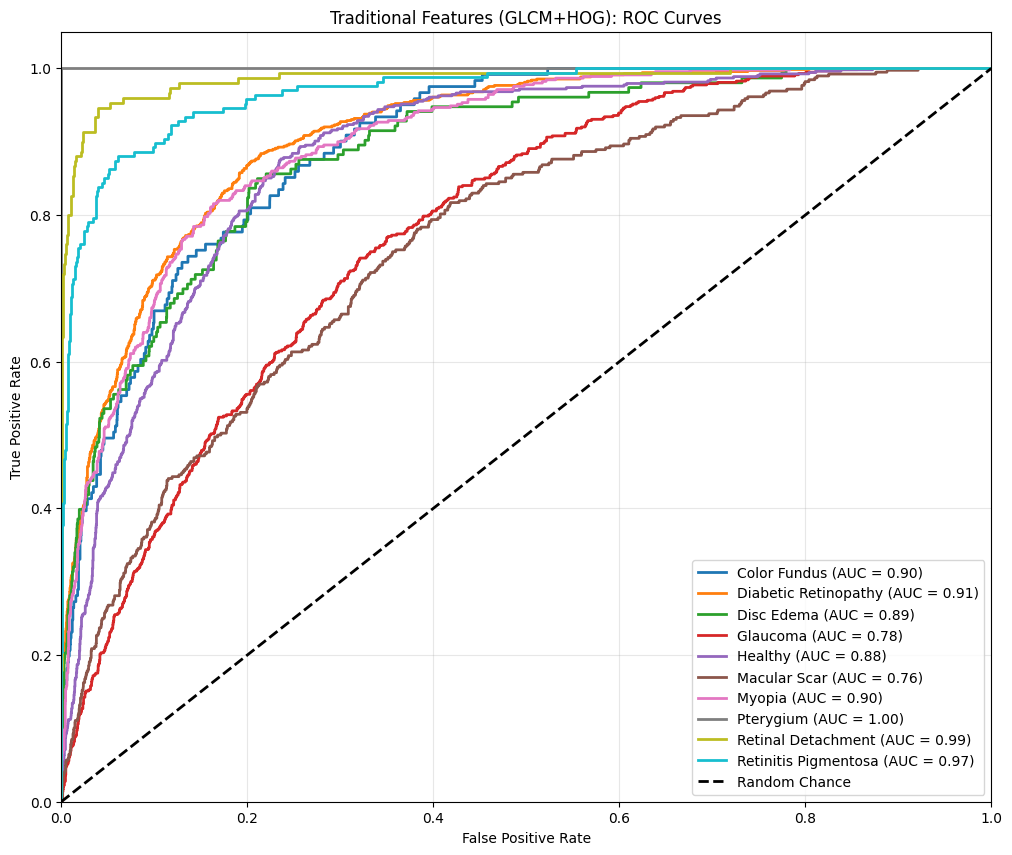

In [7]:
def extract_glcm_features(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    glcm = graycomatrix(gray, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], 
                        levels=256, symmetric=True, normed=True)
    
    contrast = graycoprops(glcm, 'contrast').flatten()
    dissimilarity = graycoprops(glcm, 'dissimilarity').flatten()
    homogeneity = graycoprops(glcm, 'homogeneity').flatten()
    energy = graycoprops(glcm, 'energy').flatten()
    correlation = graycoprops(glcm, 'correlation').flatten()

    return np.hstack([contrast, dissimilarity, homogeneity, energy, correlation])

def extract_hog_features(image):
    resized = cv2.resize(image, (128, 128)) 

    features = hog(resized, orientations=9, pixels_per_cell=(16, 16),
                   cells_per_block=(2, 2), channel_axis=-1, visualize=False)
    
    return features


X_traditional = []
y = []

# Get class names sorted alphabetically to ensure index matches
classes = sorted([d.name for d in dataset_dir.iterdir() if d.is_dir()])
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}

print(f"Classes found: {classes}")

# Extraction Loop
for cls_name in classes:
    cls_folder = dataset_dir / cls_name
    
    img_files = list(cls_folder.glob("*.*"))
    
    for img_path in tqdm(img_files, desc=f"Processing {cls_name}"):
        img = cv2.imread(str(img_path))
        if img is None: continue
            
        # Extract Features
        feat_glcm = extract_glcm_features(img) 
        feat_hog = extract_hog_features(img)   
        
        # Concatenate
        combined_features = np.hstack([feat_glcm, feat_hog])
        
        X_traditional.append(combined_features)
        y.append(class_to_idx[cls_name])

X_traditional = np.array(X_traditional)
y = np.array(y)

print(f"\nFeature Extraction Complete.")
print(f"Feature Vector Shape: {X_traditional.shape}") 



print("Training SVM on Traditional Features")

# Split Data
X_train, X_test, y_train, y_test_trad = train_test_split(X_traditional, y, test_size=0.2, random_state=42, stratify=y)

# Initialize Classifier
basic_clf = SVC(kernel='linear', probability=True, random_state=42) 
basic_clf.fit(X_train, y_train)



# Get Class Predictions 
preds_trad = basic_clf.predict(X_test)

# Get Class Probabilities
# This returns array of shape 
probs_trad = basic_clf.predict_proba(X_test)


run_evaluation_metrics(
    y_true=y_test_trad, 
    y_preds=preds_trad, 
    y_probs=probs_trad, 
    class_names=classes, 
    model="Traditional Features (GLCM+HOG)"
)

Extracting CNN Features for Retinitis Pigmentosa: 100%|██████████| 834/834 [00:40<00:00, 20.65it/s]


CNN Features Shape: (16242, 1024)
Accuracy: 0.7892
                      precision    recall  f1-score   support

        Color Fundus       0.69      0.76      0.72       132
Diabetic Retinopathy       0.91      0.93      0.92       659
          Disc Edema       0.90      0.91      0.91       163
            Glaucoma       0.63      0.70      0.66       562
             Healthy       0.74      0.71      0.72       578
        Macular Scar       0.72      0.64      0.68       396
              Myopia       0.81      0.78      0.79       428
           Pterygium       1.00      1.00      1.00        14
  Retinal Detachment       0.95      0.99      0.97       150
Retinitis Pigmentosa       0.96      0.92      0.94       167

            accuracy                           0.79      3249
           macro avg       0.83      0.83      0.83      3249
        weighted avg       0.79      0.79      0.79      3249


========== RESULTS FOR: DenseNet features + SVM (linear) ==========
Test Accu

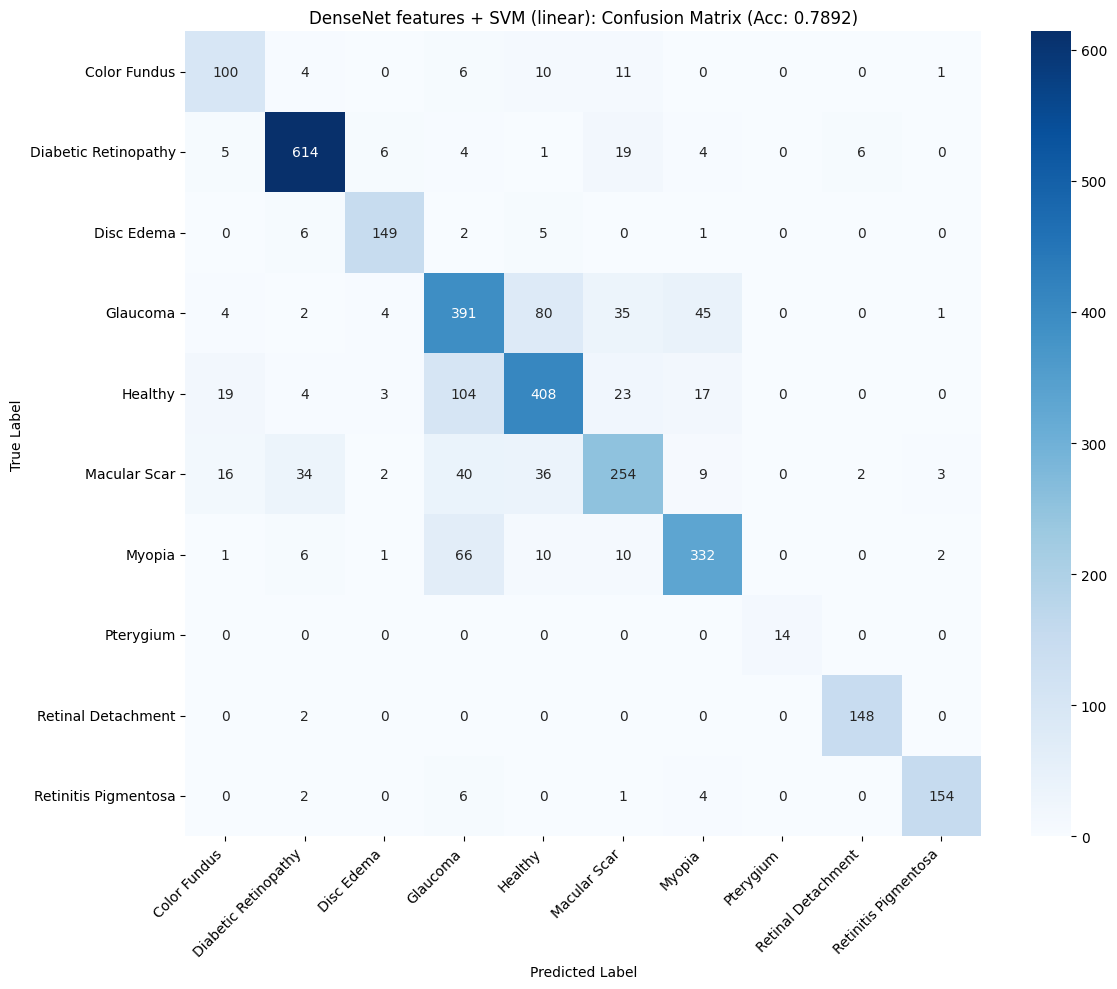

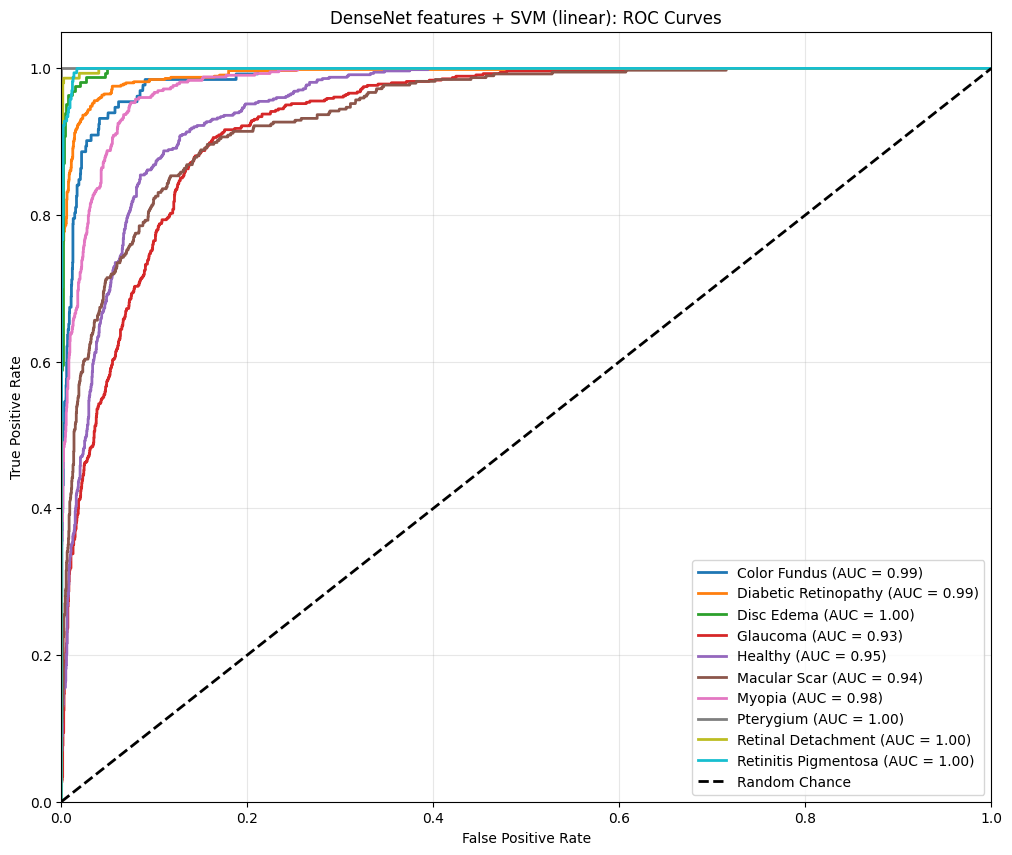

In [8]:
cnn_extractor = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)

# editing the classifier
cnn_extractor.classifier = nn.Identity()
cnn_extractor.to(device)
cnn_extractor.eval()

transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

X_cnn = []
y = []
image_paths = []

classes = sorted([d.name for d in dataset_dir.iterdir() if d.is_dir()])
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}

for cls_name in classes:
    cls_folder = dataset_dir / cls_name

    current_images = list(cls_folder.glob("*.*")) 

    for img_path in tqdm(current_images, desc=f"Extracting CNN Features for {cls_name}"): 
       img = cv2.imread(str(img_path))
       img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

       img_t = transform(img).unsqueeze(0).to(device)

       with torch.no_grad():
        features = cnn_extractor(img_t)
        features = features.cpu().numpy().flatten()

        X_cnn.append(features)
        y.append(class_to_idx[cls_name])
        image_paths.append(str(img_path))

X_cnn = np.array(X_cnn)
y = np.array(y)


print(f"CNN Features Shape: {X_cnn.shape}")

X_train_c, X_test_c, y_train_c, y_test_cnn = train_test_split(X_cnn, y, test_size=0.2, random_state=42)

cnn_clf = SVC(kernel='linear', probability=True) 
cnn_clf.fit(X_train_c, y_train_c)
preds_cnn = cnn_clf.predict(X_test_c)
probs_cnn = cnn_clf.predict_proba(X_test_c)


print(f"Accuracy: {accuracy_score(y_test_cnn, preds_cnn):.4f}")
print(classification_report(y_test_cnn, preds_cnn, target_names=classes))

run_evaluation_metrics(
    y_true=y_test_cnn,
    y_preds=preds_cnn,
    y_probs=probs_cnn,
    class_names=classes,
    model="DenseNet features + SVM (linear)"
)

Extracting Deep Features for Color Fundus: 100%|██████████| 606/606 [00:31<00:00, 19.23it/s]
Extracting Deep Features for Diabetic Retinopathy: 100%|██████████| 3444/3444 [02:50<00:00, 20.22it/s]
Extracting Deep Features for Retinal Detachment: 100%|██████████| 750/750 [00:36<00:00, 20.69it/s]
Extracting Deep Features for Retinitis Pigmentosa: 100%|██████████| 834/834 [00:39<00:00, 21.13it/s]


Deep Features Shape: (16242, 1024)

Fusing Features...
Hybrid Feature Vector Shape: (16242, 2808)
Training SVM on HYBRID Features...

 Hybrid Fusion Results
Accuracy: 0.7895
                      precision    recall  f1-score   support

        Color Fundus       0.69      0.80      0.74       132
Diabetic Retinopathy       0.91      0.94      0.92       659
          Disc Edema       0.92      0.92      0.92       163
            Glaucoma       0.63      0.70      0.66       562
             Healthy       0.73      0.69      0.71       578
        Macular Scar       0.72      0.65      0.69       396
              Myopia       0.81      0.76      0.79       428
           Pterygium       1.00      1.00      1.00        14
  Retinal Detachment       0.95      0.99      0.97       150
Retinitis Pigmentosa       0.96      0.92      0.94       167

            accuracy                           0.79      3249
           macro avg       0.83      0.84      0.83      3249
        weighted a

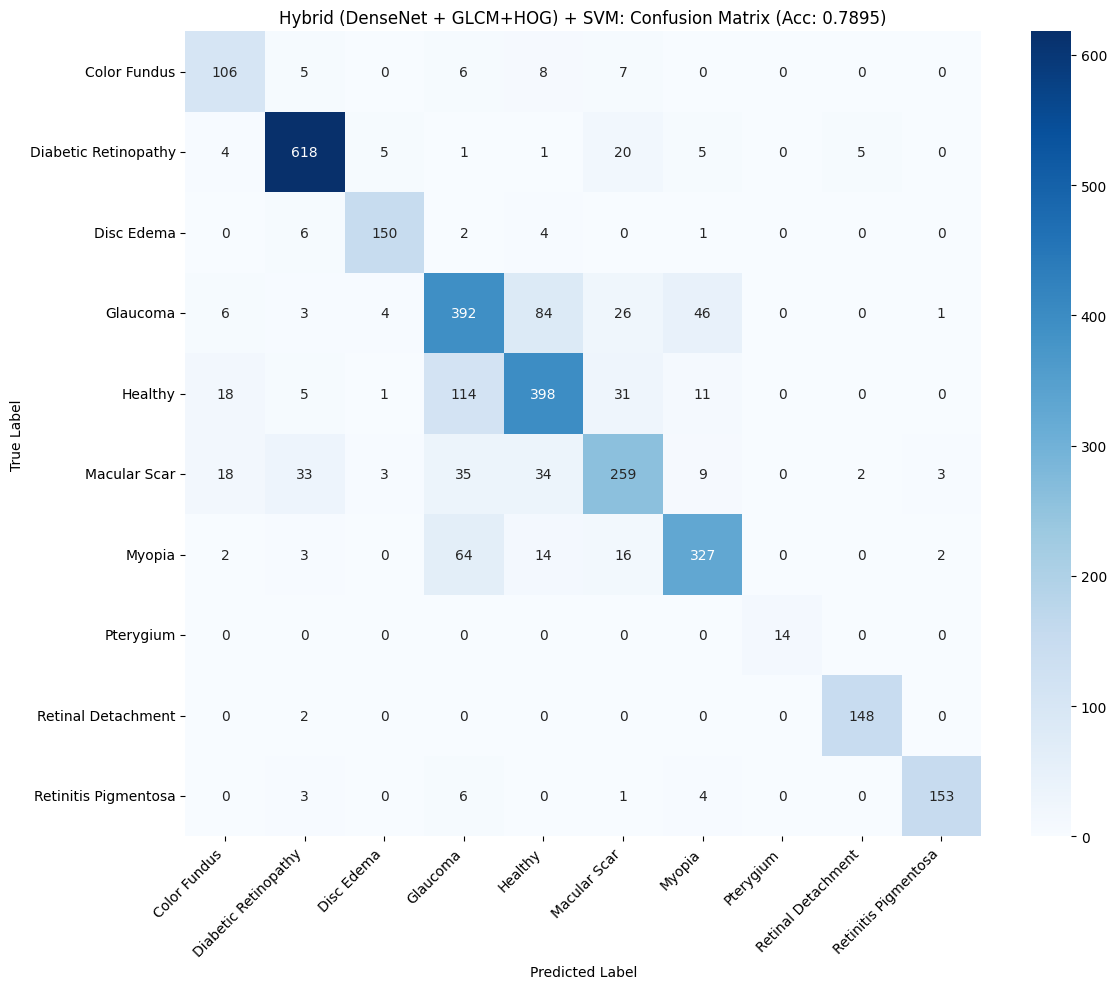

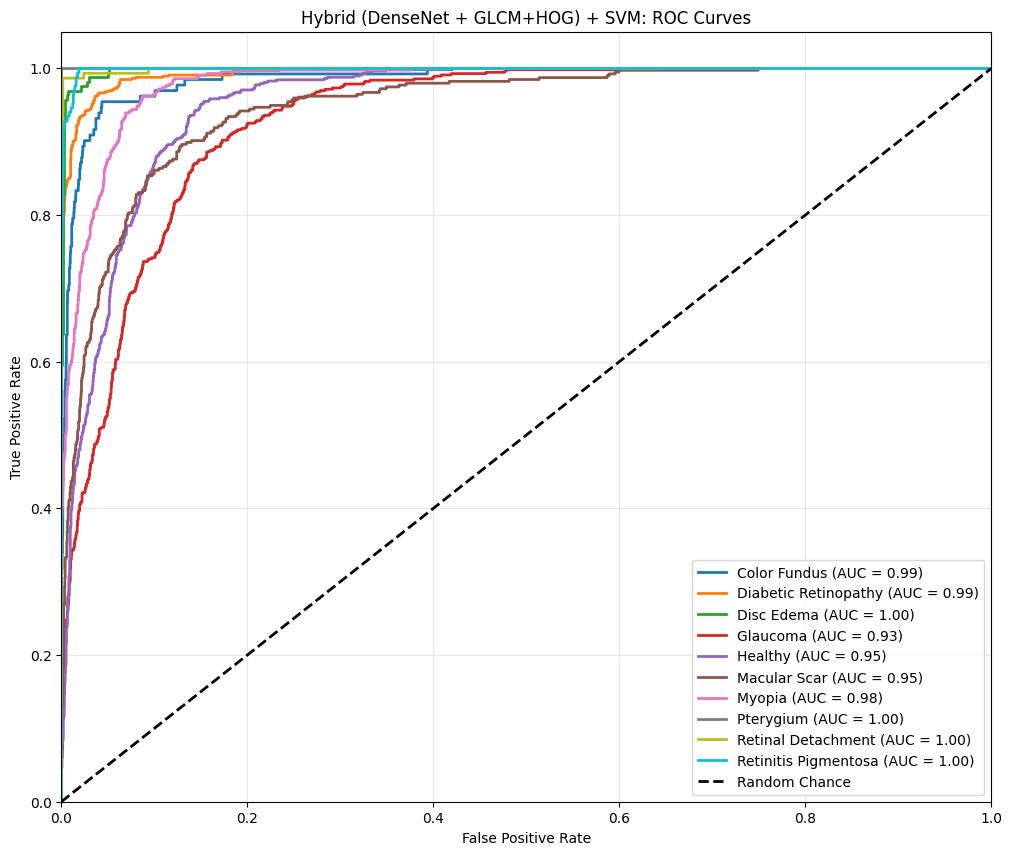

In [9]:
extractor_model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
# changing the classfier
extractor_model.classifier = nn.Identity() 

extractor_model = extractor_model.to(device)
extractor_model.eval()


transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

X_deep = []
y = []
image_paths = []


for cls_name in classes:
    cls_folder = dataset_dir / cls_name
    img_files = list(cls_folder.glob("*.*"))
    for img_path in tqdm(img_files, desc=f"Extracting Deep Features for {cls_name}"):
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_t = transform(img).unsqueeze(0).to(device)
        with torch.no_grad():
            features = extractor_model(img_t).cpu().numpy().flatten()
        X_deep.append(features)
        y.append(class_to_idx[cls_name])


X_deep = np.array(X_deep)
y = np.array(y)
print(f"Deep Features Shape: {X_deep.shape}")


print("\nFusing Features...")
# Combining Deep CNN + Traditional 
X_hybrid = np.hstack([X_deep, X_traditional])
print(f"Hybrid Feature Vector Shape: {X_hybrid.shape}")


print("Training SVM on HYBRID Features...")
X_train_h, X_test_h, y_train_h, y_test_hybrid = train_test_split(X_hybrid, y, test_size=0.2, random_state=42)

deep_cnn_clf = SVC(kernel='linear', probability=True) 
deep_cnn_clf.fit(X_train_h, y_train_h)
preds_hybrid = deep_cnn_clf.predict(X_test_h)
probs_hybrid = deep_cnn_clf.predict_proba(X_test_h)

print("\n Hybrid Fusion Results")
print(f"Accuracy: {accuracy_score(y_test_hybrid, preds_hybrid):.4f}")
print(classification_report(y_test_hybrid, preds_hybrid, target_names=classes))
run_evaluation_metrics(y_test_hybrid, preds_hybrid, probs_hybrid, classes, "Hybrid (DenseNet + GLCM+HOG) + SVM")

In [11]:
def run_evaluation_metrics(y_true, y_preds, y_probs, class_names, model):

    num_classes = len(class_names)
    
    # 1. Calculate Metrics
    accuracy = accuracy_score(y_true, y_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_preds, average=None)
    macro_f1 = f1.mean()
    weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(y_true, y_preds, average='weighted')
    kappa = cohen_kappa_score(y_true, y_preds)
    mcc = matthews_corrcoef(y_true, y_preds)
    
    # Sensitivity & Specificity
    sensitivity = sensitivity_score(y_true, y_preds, average='macro')
    specificity = specificity_score(y_true, y_preds, average='macro')

    # AUC Scores
    try:
        auc_ovr = roc_auc_score(y_true, y_probs, multi_class='ovr', average='weighted')
        auc_macro = roc_auc_score(y_true, y_probs, multi_class='ovr', average='macro')
        auc_weighted = roc_auc_score(y_true, y_probs, multi_class='ovr', average='weighted')
    except Exception as e:
        print(f"Could not calculate AUC: {e}")
        auc_ovr, auc_macro, auc_weighted = 0, 0, 0

    # 2. Print Text Report (console output – no change)
    print(f"\n{'='*10} RESULTS FOR: {model} {'='*10}")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"Cohen's Kappa: {kappa:.4f}")
    print(f"MCC: {mcc:.4f}")
    print(f"Macro Sensitivity (Recall): {sensitivity:.4f}")
    print(f"Macro Specificity: {specificity:.4f}")
    print("\nPer-Class Performance:")
    for i, name in enumerate(class_names):
        print(f"  {name:15s}  Precision: {precision[i]:.4f}  Recall: {recall[i]:.4f}  F1: {f1[i]:.4f}")
    print(f"\nMacro F1-score: {macro_f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")
    print(f"Weighted AUC: {auc_ovr:.4f}")
    print(f"Macro AUC (OvR): {auc_macro:.4f}")
    print(f"Weighted AUC (OvR): {auc_weighted:.4f}")
    
    print("\nClassification Report:\n")
    print(classification_report(y_true, y_preds, target_names=class_names))

    # 3. Confusion Matrix Plot (with bold text)
    cm = confusion_matrix(y_true, y_preds)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                annot_kws={'fontweight':'bold'})               # bold annotations
    plt.title(f'{model}: Confusion Matrix (Acc: {accuracy:.4f})', fontweight='bold')
    plt.xlabel('Predicted Label', fontweight='bold')
    plt.ylabel('True Label', fontweight='bold')
    plt.xticks(rotation=45, ha='right', fontweight='bold')
    plt.yticks(fontweight='bold')
    # Make colorbar tick labels bold
    cbar = plt.gca().collections[0].colorbar
    cbar.ax.tick_params(labelsize=10)
    for label in cbar.ax.get_yticklabels():
        label.set_fontweight('bold')
    plt.tight_layout()
    plt.show()

    # 4. ROC Curves Plot (with bold text)
    y_true_bin = label_binarize(y_true, classes=range(num_classes))
    
    plt.figure(figsize=(12, 10))
    colors = plt.cm.tab10(np.linspace(0, 1, num_classes))

    for i, color in zip(range(num_classes), colors):
        if np.sum(y_true == i) > 0:  # Only plot if class exists in test set
            fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, color=color, lw=2,
                     label=f'{class_names[i]} (AUC = {roc_auc:.2f})')
    
    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Chance')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontweight='bold')
    plt.ylabel('True Positive Rate', fontweight='bold')
    plt.title(f'{model}: ROC Curves', fontweight='bold')
    plt.legend(loc="lower right", prop={'weight':'bold'})      # bold legend text
    plt.grid(True, alpha=0.3)
    plt.xticks(fontweight='bold')
    plt.yticks(fontweight='bold')
    plt.show()


========== RESULTS FOR: DenseNet features + SVM (linear) ==========
Test Accuracy: 0.7892
Cohen's Kappa: 0.7536
MCC: 0.7539
Macro Sensitivity (Recall): 0.8331
Macro Specificity: 0.9751

Per-Class Performance:
  Color Fundus     Precision: 0.6897  Recall: 0.7576  F1: 0.7220
  Diabetic Retinopathy  Precision: 0.9110  Recall: 0.9317  F1: 0.9212
  Disc Edema       Precision: 0.9030  Recall: 0.9141  F1: 0.9085
  Glaucoma         Precision: 0.6317  Recall: 0.6957  F1: 0.6622
  Healthy          Precision: 0.7418  Recall: 0.7059  F1: 0.7234
  Macular Scar     Precision: 0.7195  Recall: 0.6414  F1: 0.6782
  Myopia           Precision: 0.8058  Recall: 0.7757  F1: 0.7905
  Pterygium        Precision: 1.0000  Recall: 1.0000  F1: 1.0000
  Retinal Detachment  Precision: 0.9487  Recall: 0.9867  F1: 0.9673
  Retinitis Pigmentosa  Precision: 0.9565  Recall: 0.9222  F1: 0.9390

Macro F1-score: 0.8312
Weighted F1: 0.7890
Weighted AUC: 0.9679
Macro AUC (OvR): 0.9783
Weighted AUC (OvR): 0.9679

Classifica

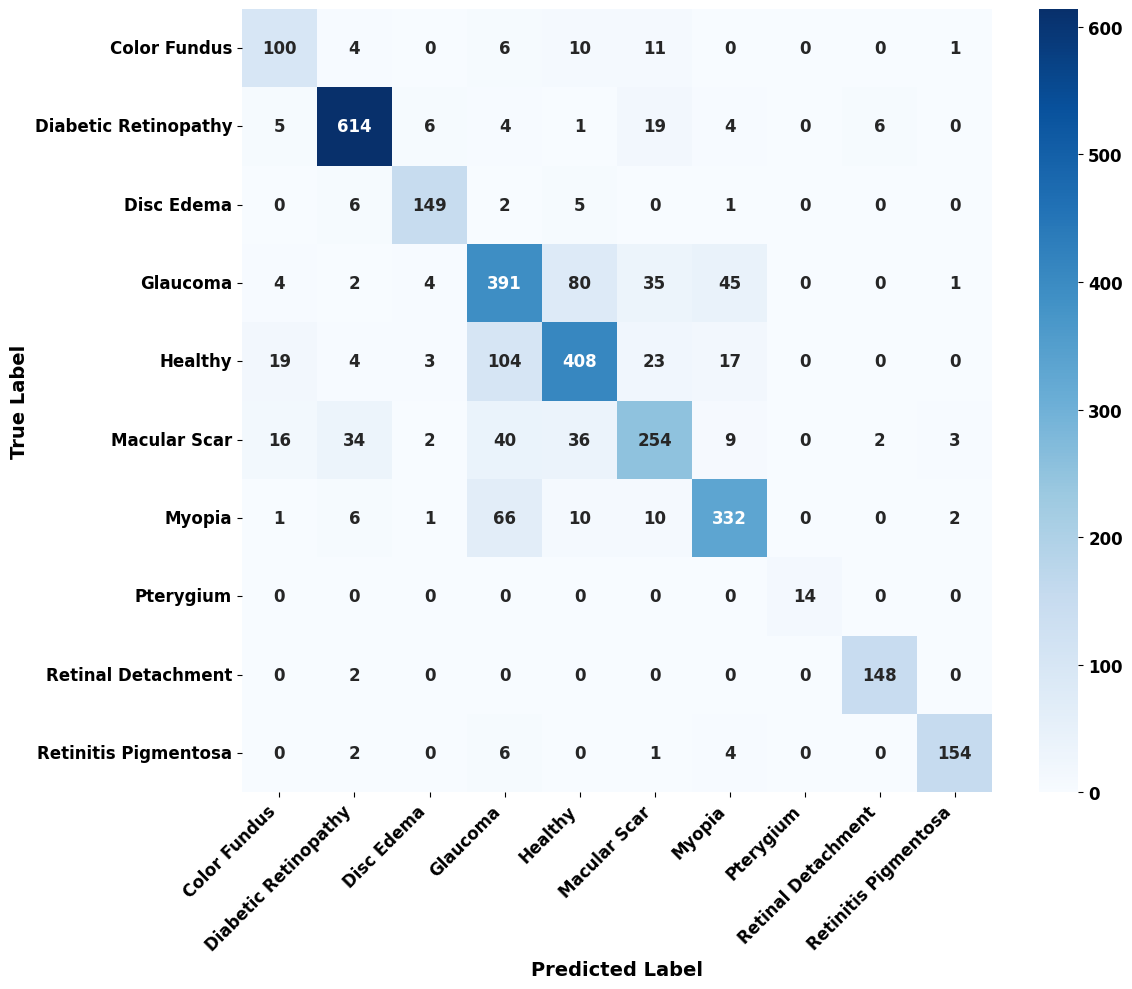

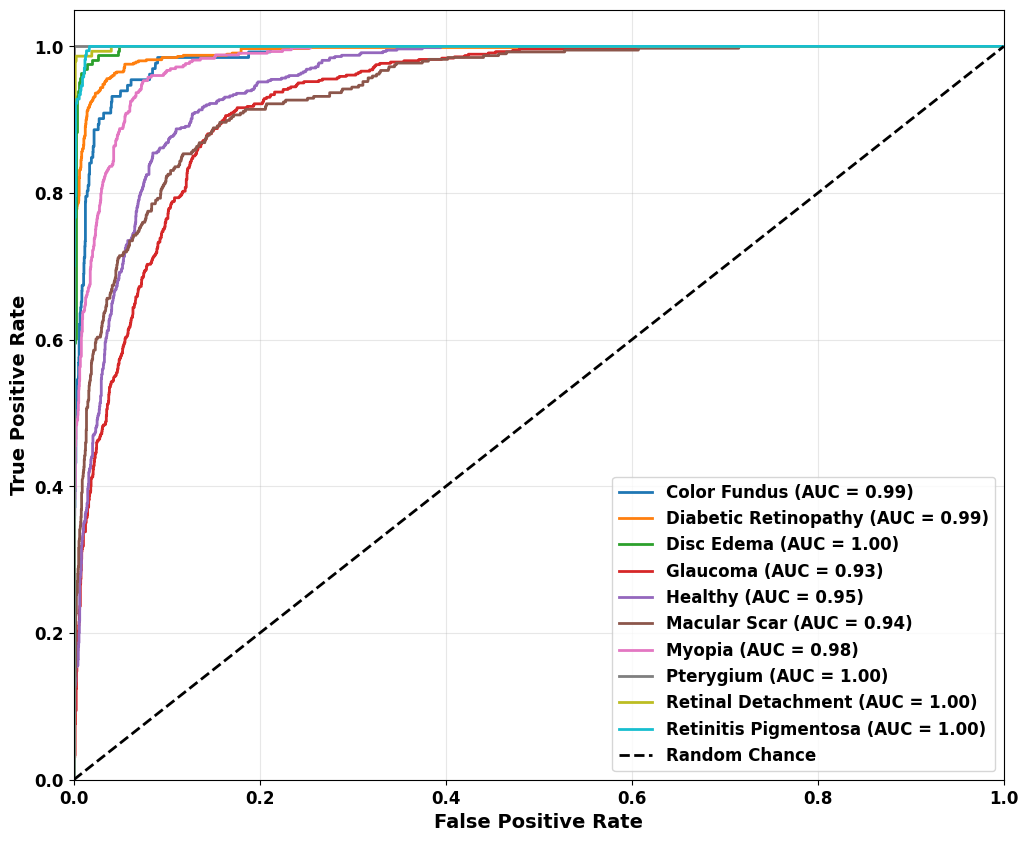

In [18]:
run_evaluation_metrics(
    y_true=y_test_cnn,
    y_preds=preds_cnn,
    y_probs=probs_cnn,
    class_names=classes,
    model="DenseNet features + SVM (linear)"
)

In [15]:
def run_evaluation_metrics(y_true, y_preds, y_probs, class_names, model):

    num_classes = len(class_names)
    
    # 1. Calculate Metrics
    accuracy = accuracy_score(y_true, y_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_preds, average=None)
    macro_f1 = f1.mean()
    weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(y_true, y_preds, average='weighted')
    kappa = cohen_kappa_score(y_true, y_preds)
    mcc = matthews_corrcoef(y_true, y_preds)
    
    # Sensitivity & Specificity
    sensitivity = sensitivity_score(y_true, y_preds, average='macro')
    specificity = specificity_score(y_true, y_preds, average='macro')

    # AUC Scores
    try:
        auc_ovr = roc_auc_score(y_true, y_probs, multi_class='ovr', average='weighted')
        auc_macro = roc_auc_score(y_true, y_probs, multi_class='ovr', average='macro')
        auc_weighted = roc_auc_score(y_true, y_probs, multi_class='ovr', average='weighted')
    except Exception as e:
        print(f"Could not calculate AUC: {e}")
        auc_ovr, auc_macro, auc_weighted = 0, 0, 0

    # 2. Print Text Report (unchanged)
    print(f"\n{'='*10} RESULTS FOR: {model} {'='*10}")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"Cohen's Kappa: {kappa:.4f}")
    print(f"MCC: {mcc:.4f}")
    print(f"Macro Sensitivity (Recall): {sensitivity:.4f}")
    print(f"Macro Specificity: {specificity:.4f}")
    print("\nPer-Class Performance:")
    for i, name in enumerate(class_names):
        print(f"  {name:15s}  Precision: {precision[i]:.4f}  Recall: {recall[i]:.4f}  F1: {f1[i]:.4f}")
    print(f"\nMacro F1-score: {macro_f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")
    print(f"Weighted AUC: {auc_ovr:.4f}")
    print(f"Macro AUC (OvR): {auc_macro:.4f}")
    print(f"Weighted AUC (OvR): {auc_weighted:.4f}")
    
    print("\nClassification Report:\n")
    print(classification_report(y_true, y_preds, target_names=class_names))

    # 3. Confusion Matrix Plot (larger bold text)
    cm = confusion_matrix(y_true, y_preds)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                annot_kws={'fontweight':'bold', 'fontsize':12})      # larger bold annotations
  
    plt.xlabel('Predicted Label', fontweight='bold', fontsize=14)
    plt.ylabel('True Label', fontweight='bold', fontsize=14)
    plt.xticks(rotation=45, ha='right', fontweight='bold', fontsize=12)
    plt.yticks(fontweight='bold', fontsize=12)
    # Make colorbar tick labels bold and larger
    cbar = plt.gca().collections[0].colorbar
    cbar.ax.tick_params(labelsize=12)
    for label in cbar.ax.get_yticklabels():
        label.set_fontweight('bold')
    plt.tight_layout()
    plt.show()

    # 4. ROC Curves Plot (larger bold text)
    y_true_bin = label_binarize(y_true, classes=range(num_classes))
    
    plt.figure(figsize=(12, 10))
    colors = plt.cm.tab10(np.linspace(0, 1, num_classes))

    for i, color in zip(range(num_classes), colors):
        if np.sum(y_true == i) > 0:  # Only plot if class exists in test set
            fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, color=color, lw=2,
                     label=f'{class_names[i]} (AUC = {roc_auc:.2f})')
    
    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Chance')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontweight='bold', fontsize=14)
    plt.ylabel('True Positive Rate', fontweight='bold', fontsize=14)
   
    plt.legend(loc="lower right", prop={'weight':'bold', 'size':12})  # larger bold legend
    plt.grid(True, alpha=0.3)
    plt.xticks(fontweight='bold', fontsize=12)
    plt.yticks(fontweight='bold', fontsize=12)
    plt.show()


========== RESULTS FOR: Traditional Features (GLCM+HOG) ==========
Test Accuracy: 0.5463
Cohen's Kappa: 0.4649
MCC: 0.4657
Macro Sensitivity (Recall): 0.5747
Macro Specificity: 0.9462

Per-Class Performance:
  Color Fundus     Precision: 0.3939  Recall: 0.3223  F1: 0.3545
  Diabetic Retinopathy  Precision: 0.6255  Recall: 0.7344  F1: 0.6756
  Disc Edema       Precision: 0.4793  Recall: 0.3791  F1: 0.4234
  Glaucoma         Precision: 0.4023  Recall: 0.4323  F1: 0.4167
  Healthy          Precision: 0.5375  Recall: 0.5626  F1: 0.5498
  Macular Scar     Precision: 0.3729  Recall: 0.2912  F1: 0.3271
  Myopia           Precision: 0.5865  Recall: 0.5800  F1: 0.5832
  Pterygium        Precision: 1.0000  Recall: 1.0000  F1: 1.0000
  Retinal Detachment  Precision: 0.8806  Recall: 0.7867  F1: 0.8310
  Retinitis Pigmentosa  Precision: 0.7914  Recall: 0.6587  F1: 0.7190

Macro F1-score: 0.5880
Weighted F1: 0.5421
Weighted AUC: 0.8684
Macro AUC (OvR): 0.8969
Weighted AUC (OvR): 0.8684

Classificat

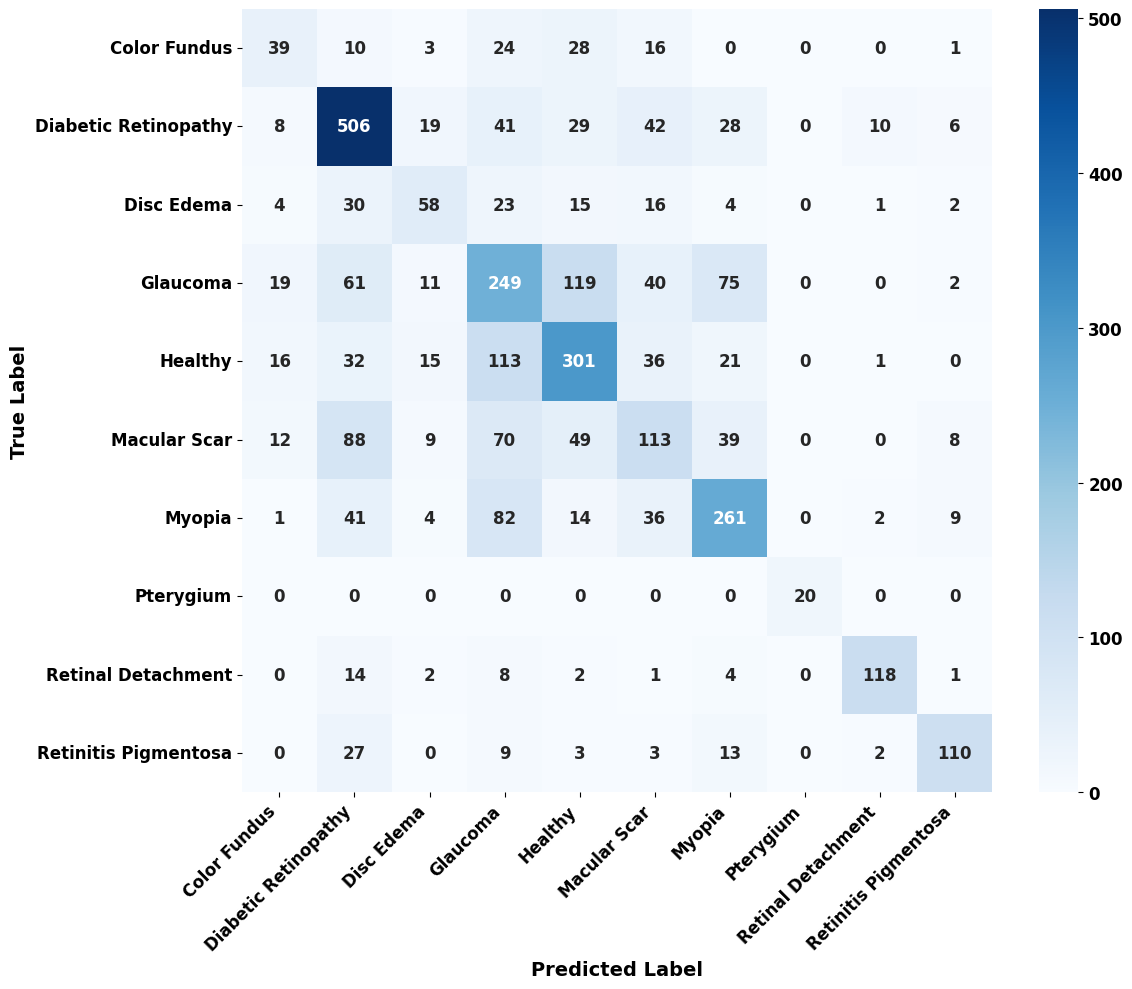

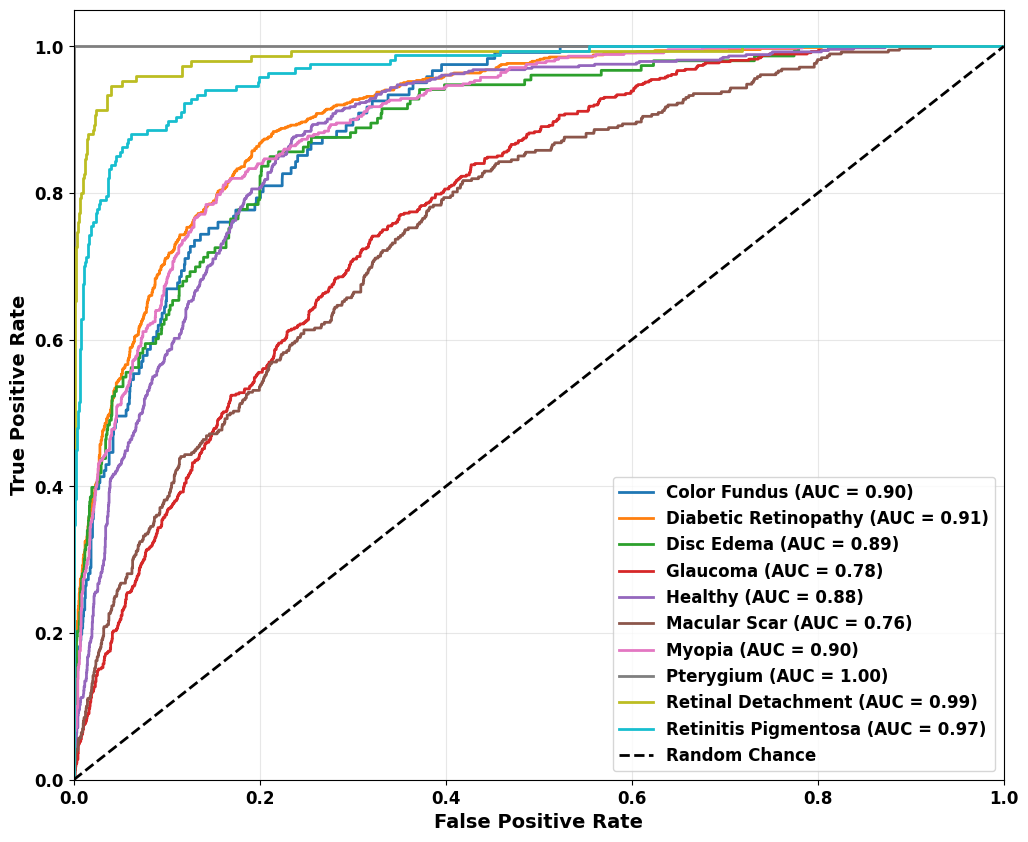

In [19]:
run_evaluation_metrics(
    y_true=y_test_trad, 
    y_preds=preds_trad, 
    y_probs=probs_trad, 
    class_names=classes, 
    model="Traditional Features (GLCM+HOG)"
)


========== RESULTS FOR: Hybrid (DenseNet + GLCM+HOG) + SVM ==========
Test Accuracy: 0.7895
Cohen's Kappa: 0.7540
MCC: 0.7543
Macro Sensitivity (Recall): 0.8368
Macro Specificity: 0.9752

Per-Class Performance:
  Color Fundus     Precision: 0.6883  Recall: 0.8030  F1: 0.7413
  Diabetic Retinopathy  Precision: 0.9115  Recall: 0.9378  F1: 0.9245
  Disc Edema       Precision: 0.9202  Recall: 0.9202  F1: 0.9202
  Glaucoma         Precision: 0.6323  Recall: 0.6975  F1: 0.6633
  Healthy          Precision: 0.7330  Recall: 0.6886  F1: 0.7101
  Macular Scar     Precision: 0.7194  Recall: 0.6540  F1: 0.6852
  Myopia           Precision: 0.8114  Recall: 0.7640  F1: 0.7870
  Pterygium        Precision: 1.0000  Recall: 1.0000  F1: 1.0000
  Retinal Detachment  Precision: 0.9548  Recall: 0.9867  F1: 0.9705
  Retinitis Pigmentosa  Precision: 0.9623  Recall: 0.9162  F1: 0.9387

Macro F1-score: 0.8341
Weighted F1: 0.7894
Weighted AUC: 0.9690
Macro AUC (OvR): 0.9789
Weighted AUC (OvR): 0.9690

Classifi

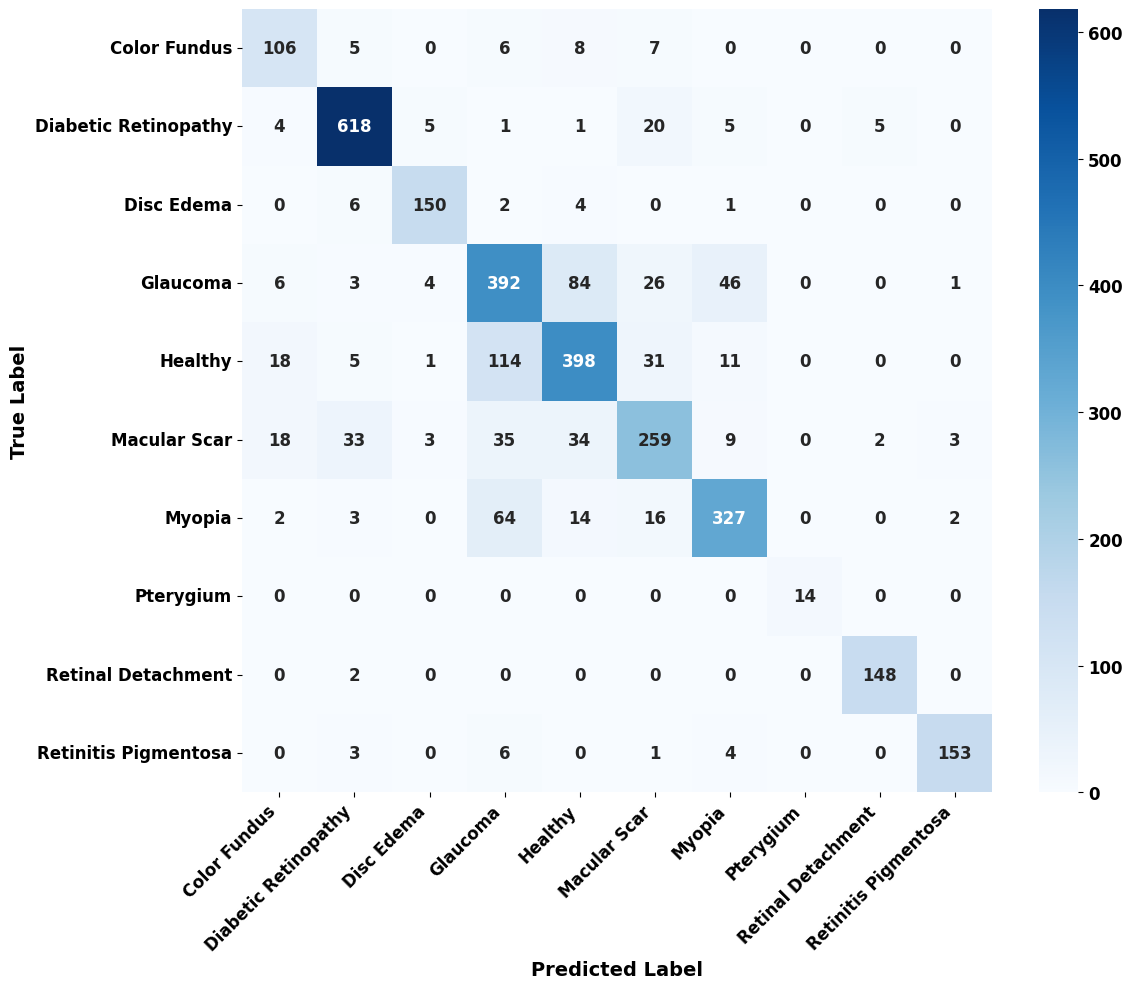

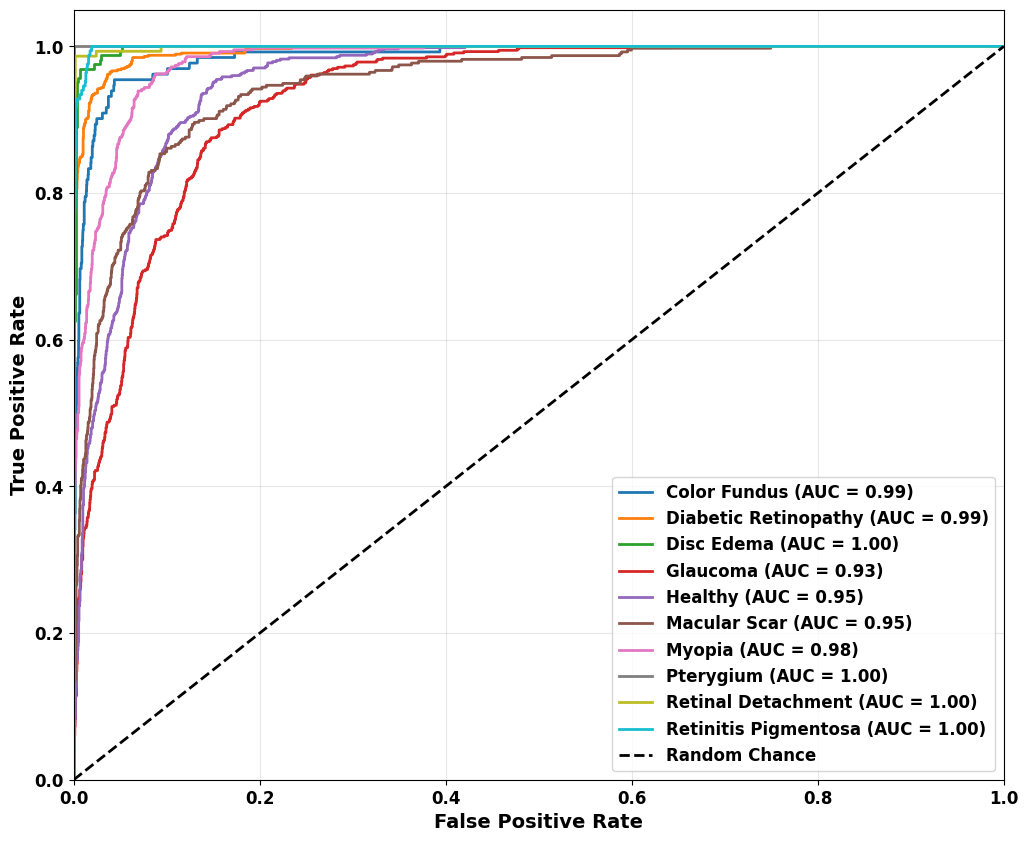

In [16]:
run_evaluation_metrics(y_test_hybrid, preds_hybrid, probs_hybrid, classes, "Hybrid (DenseNet + GLCM+HOG) + SVM")